# Measuring Matter Antimatter Asymmetries at the Large Hadron Collider

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm
import scipy.stats

import lhcb_freq as lf   # functions + settings live in lhcb_freq.py

In [2]:
# All the settings in one place (fit window, signal region, preselection cuts, n. of exponentials, limits, ...)
cfg = lf.Config(
    data_dir=Path(r"C:\\Users\\marco\\Documents\\Università\\Anno IV\\Statistics_and_Data_Analysis\\Data"),
    sim_file=Path(r"C:\\Users\\marco\\Documents\\Università\\Anno IV\\Statistics_and_Data_Analysis\\Data\\PhaseSpaceSimulation.root"),
)
cfg

Config(data_dir=WindowsPath('C:/Users/marco/Documents/Università/Anno IV/Statistics_and_Data_Analysis/Data'), data_files=('B2HHH_MagnetDown.root', 'B2HHH_MagnetUp.root'), data_tree='DecayTree', sim_file=WindowsPath('C:/Users/marco/Documents/Università/Anno IV/Statistics_and_Data_Analysis/Data/PhaseSpaceSimulation.root'), sim_tree='PhaseSpaceTree', n_products=3, m_K=493.677, m_Pi=139.57039, m_B=5279.41, prob_k_min=0.5, prob_pi_max=0.5, prob_pi_min=0.5, prob_k_max=0.5, fit_window=(5100.0, 5600.0), sig_region=(5200.0, 5350.0), n_exp=2, limits={'N_sig': (0, None), 'N_bkg': (0, None), 'A_CP': (-1.0, 1.0), 'sigma': (1.0, 100.0), 'lam': (1e-06, 1.0), 'f_bkgs': (0.0, 1.0)})

## Simulation Data

In [3]:
df_sim = lf.load_tree(cfg.sim_file, cfg.sim_tree)
print(df_sim.columns.tolist())
df_sim.head()

['B_FlightDistance', 'B_VertexChi2', 'H1_PX', 'H1_PY', 'H1_PZ', 'H1_ProbK', 'H1_ProbPi', 'H1_Charge', 'H1_IPChi2', 'H1_isMuon', 'H2_PX', 'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi', 'H2_Charge', 'H2_IPChi2', 'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK', 'H3_ProbPi', 'H3_Charge', 'H3_IPChi2', 'H3_isMuon']


,B_FlightDistance,B_VertexChi2,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_IPChi2,H1_isMuon,...,H2_IPChi2,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_IPChi2,H3_isMuon
0,0.0,1.0,3551.84,1636.96,23904.14,1.0,0.0,-1,1.0,0,...,1.0,0,36100.40,16546.83,295600.61,1.0,0.0,-1,1.0,0
1,0.0,1.0,-2525.98,-5284.05,35822.00,1.0,0.0,1,1.0,0,...,1.0,0,-8648.32,-16617.56,98535.13,1.0,0.0,-1,1.0,0
2,0.0,1.0,-700.67,1299.73,8127.76,1.0,0.0,-1,1.0,0,...,1.0,0,-13483.34,10860.77,79787.59,1.0,0.0,1,1.0,0
3,0.0,1.0,3364.63,1397.30,222815.29,1.0,0.0,1,1.0,0,...,1.0,0,1925.16,-551.12,40420.96,1.0,0.0,1,1.0,0
4,0.0,1.0,-581.66,-1305.24,22249.59,1.0,0.0,-1,1.0,0,...,1.0,0,-2820.04,-8305.43,250130.00,1.0,0.0,-1,1.0,0


### Data exploration

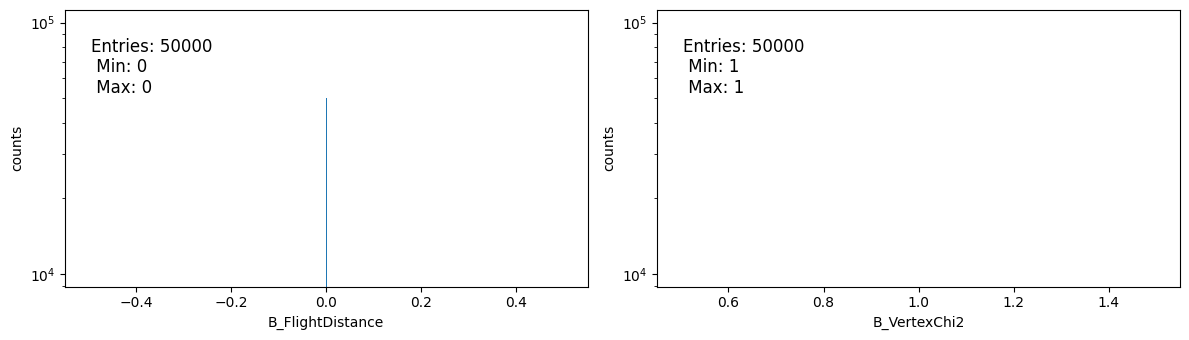

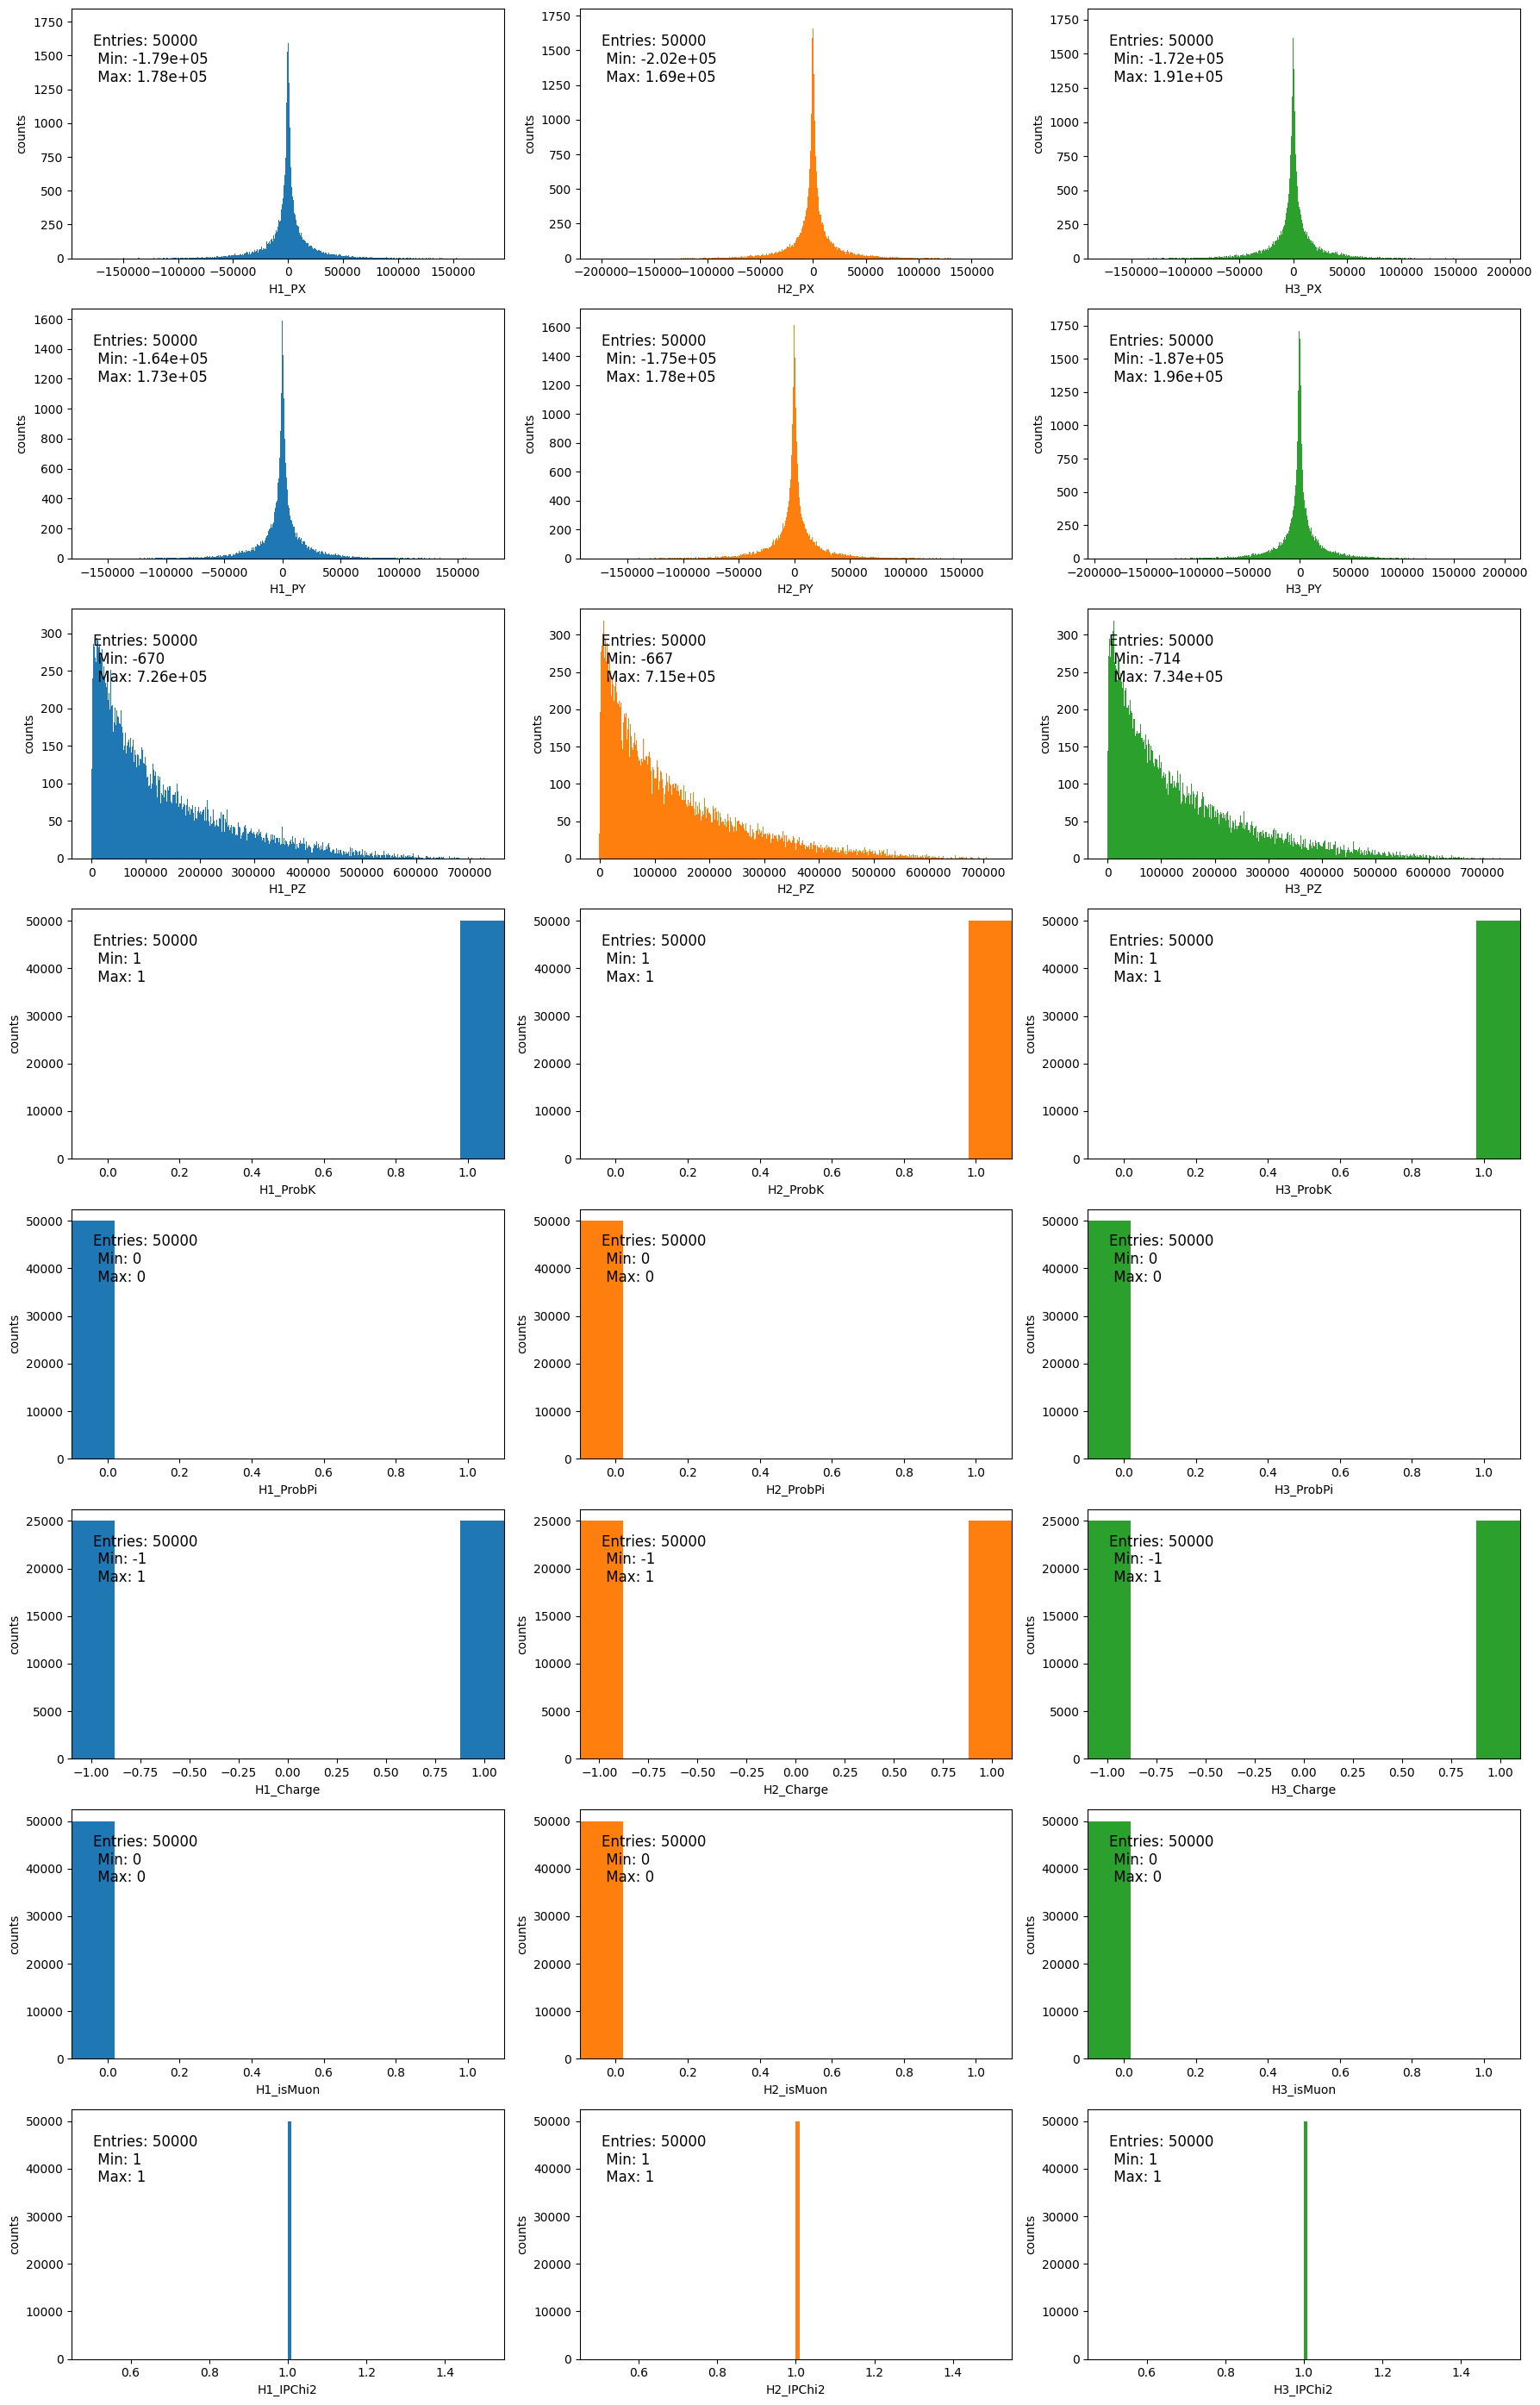

In [4]:
figs = lf.plot_all_features(df_sim, lf.GLOBAL_FEATURES, lf.PRODUCT_FEATURES + lf.EXTRA_PRODUCT_FEATURES,
                            lf.PLOT_SETTINGS["sim"], cfg.n_products)

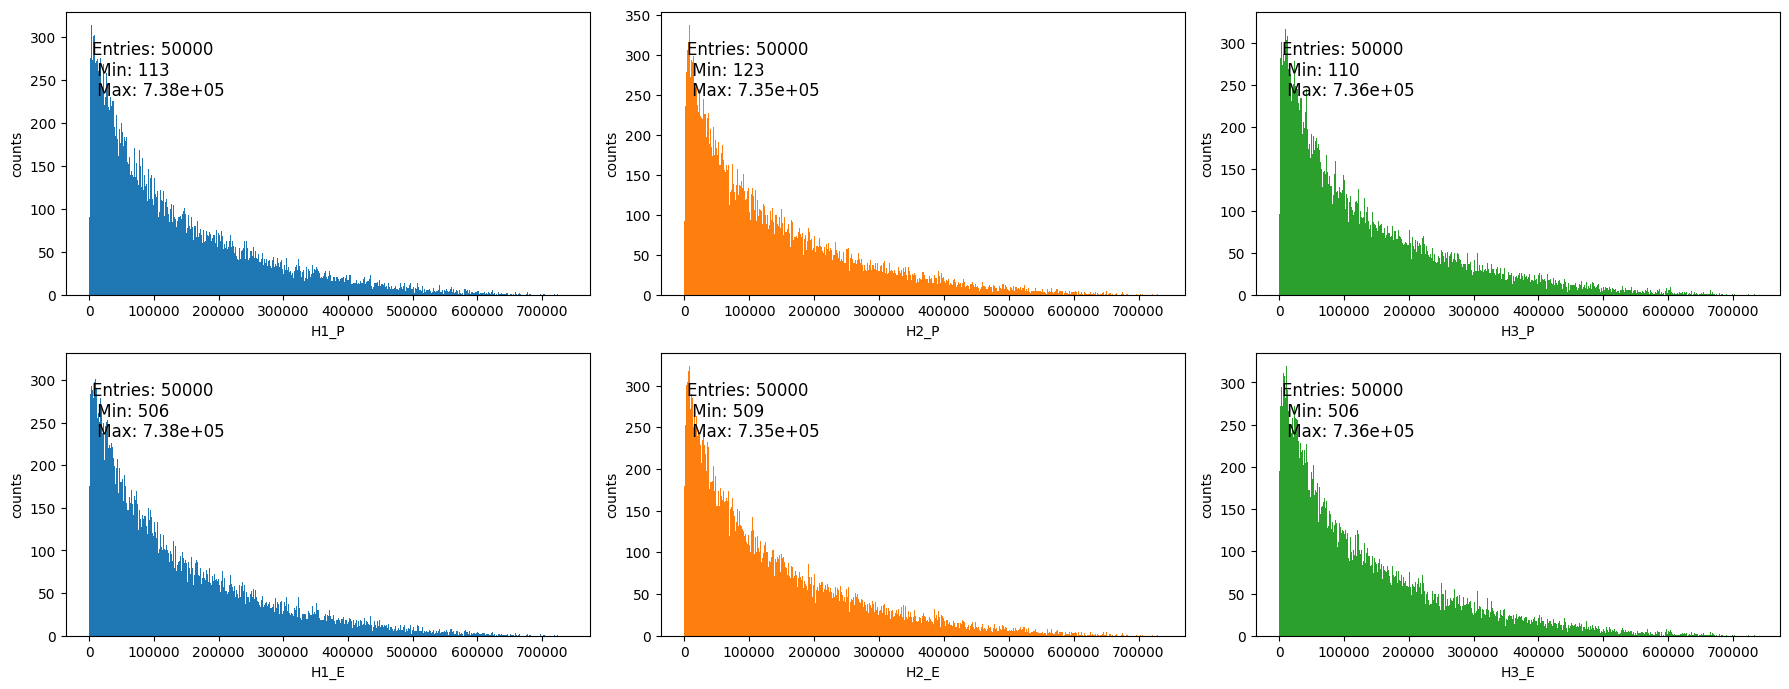

In [5]:
# New features: momentum magnitude and energy of each product
lf.add_kinematics(df_sim, cfg)
figs = lf.plot_all_features(df_sim, product_features=["P", "E"], settings=lf.PLOT_SETTINGS["sim"], n_products=cfg.n_products)

### Compute Invariant Mass

In [6]:
lf.add_B_variables(df_sim, cfg)      # adds B_Mass and B_Charge
df_sim[["B_Mass", "B_Charge"]].describe()

,B_Mass,B_Charge
count,50000.000000,50000.00000
mean,5267.883223,0.00000
std,80.964681,1.00001
min,2909.905221,-1.00000
25%,5279.241654,-1.00000
50%,5279.248254,0.00000
75%,5279.253599,1.00000
max,5279.279077,1.00000


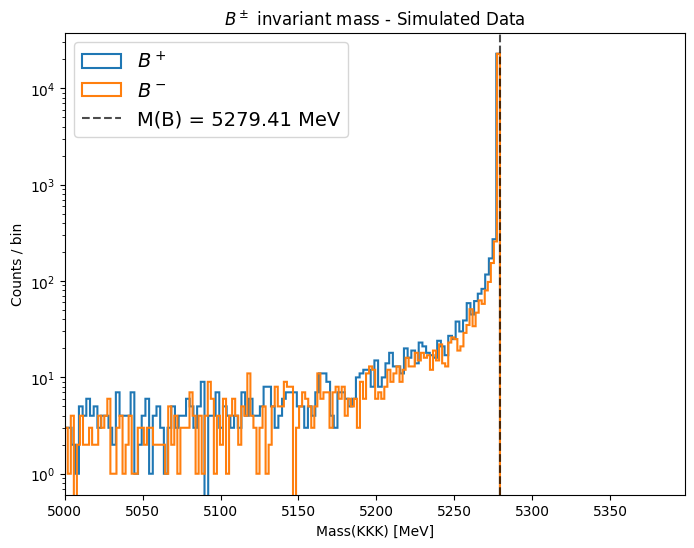

In [7]:
lf.plot_mass_by_charge(df_sim, cfg, bins=1000, logy=True, xlim=(5000, None),
                       title=r"$B^\pm$ invariant mass - Simulated Data");

max |m_vector - m_numpy| = 2.7284841053187847e-12 MeV


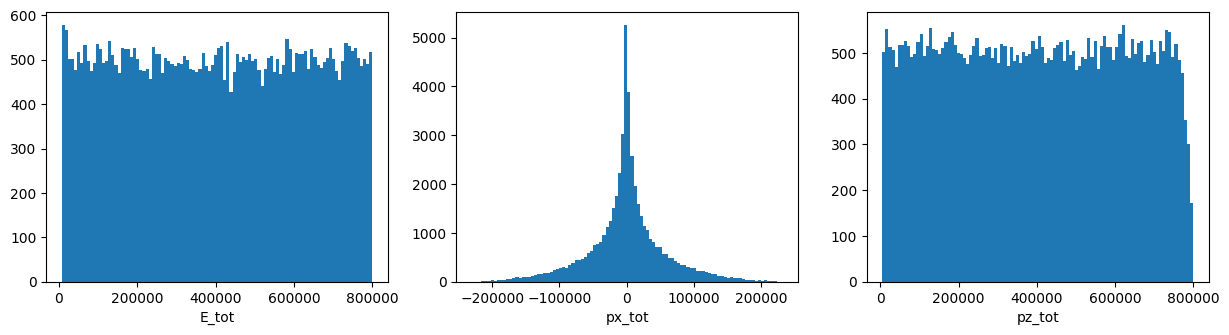

In [8]:
# Independent cross-check of the `vector` result with plain numpy (energy/momentum conservation, m^2 = E^2 - p^2)
E_tot = sum(np.sqrt(sum(df_sim[f"H{i}_{c}"]**2 for c in ("PX", "PY", "PZ")) + cfg.m_K**2) for i in cfg.particles)
p_tot = {c: sum(df_sim[f"H{i}_{c}"] for i in cfg.particles) for c in ("PX", "PY", "PZ")}
m_manual = np.sqrt(E_tot**2 - sum(v**2 for v in p_tot.values()))
print("max |m_vector - m_numpy| =", np.abs(m_manual - df_sim["B_Mass"]).max(), "MeV")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (name, v) in zip(axes, {"E_tot": E_tot, "px_tot": p_tot["PX"], "pz_tot": p_tot["PZ"]}.items()):
    ax.hist(v, bins=100)
    ax.set_xlabel(name)

# Real Data

#### Load Data

In [9]:
all_data = lf.load_data(cfg)
print("total events read:", len(all_data))
all_data.head()

total events read: 8556118


,B_FlightDistance,B_VertexChi2,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_IPChi2,H1_isMuon,...,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_IPChi2,H3_isMuon,magnet
0,25.301004,1.497280,375.284205,831.308481,51820.233718,0.038616,0.888755,-1,212.776776,0,...,0,-208.210960,-2586.359121,105848.271681,0.193004,0.138845,1,61.157888,1,down
1,94.690700,1.383338,-4985.130785,5853.750057,326157.454706,0.073556,0.039064,-1,373.815885,1,...,1,-175.018535,1325.178792,87681.561846,0.080397,0.758603,1,185.092016,0,down
2,8.284490,5.187101,-1265.456544,2330.050788,90762.658032,0.030095,0.636693,1,53.187855,0,...,0,-1383.996490,-71.081104,85574.929582,0.750751,0.399602,-1,1.481413,0,down
3,5.590769,7.129099,-720.797259,3413.790588,86793.058768,0.211414,0.350969,-1,6.232666,0,...,0,398.775944,-1134.914464,14653.316611,0.005698,0.964705,1,468.174038,0,down
4,3.013242,10.988701,397.754571,1791.373059,40040.364159,0.005697,0.933102,-1,3.137287,0,...,0,477.148467,2113.439057,24462.076980,0.002979,0.918983,1,60.530372,0,down


#### Data Exploration

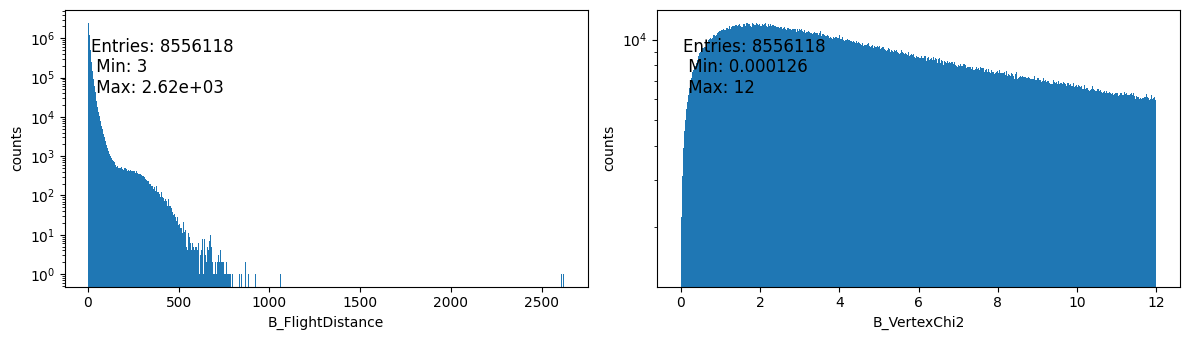

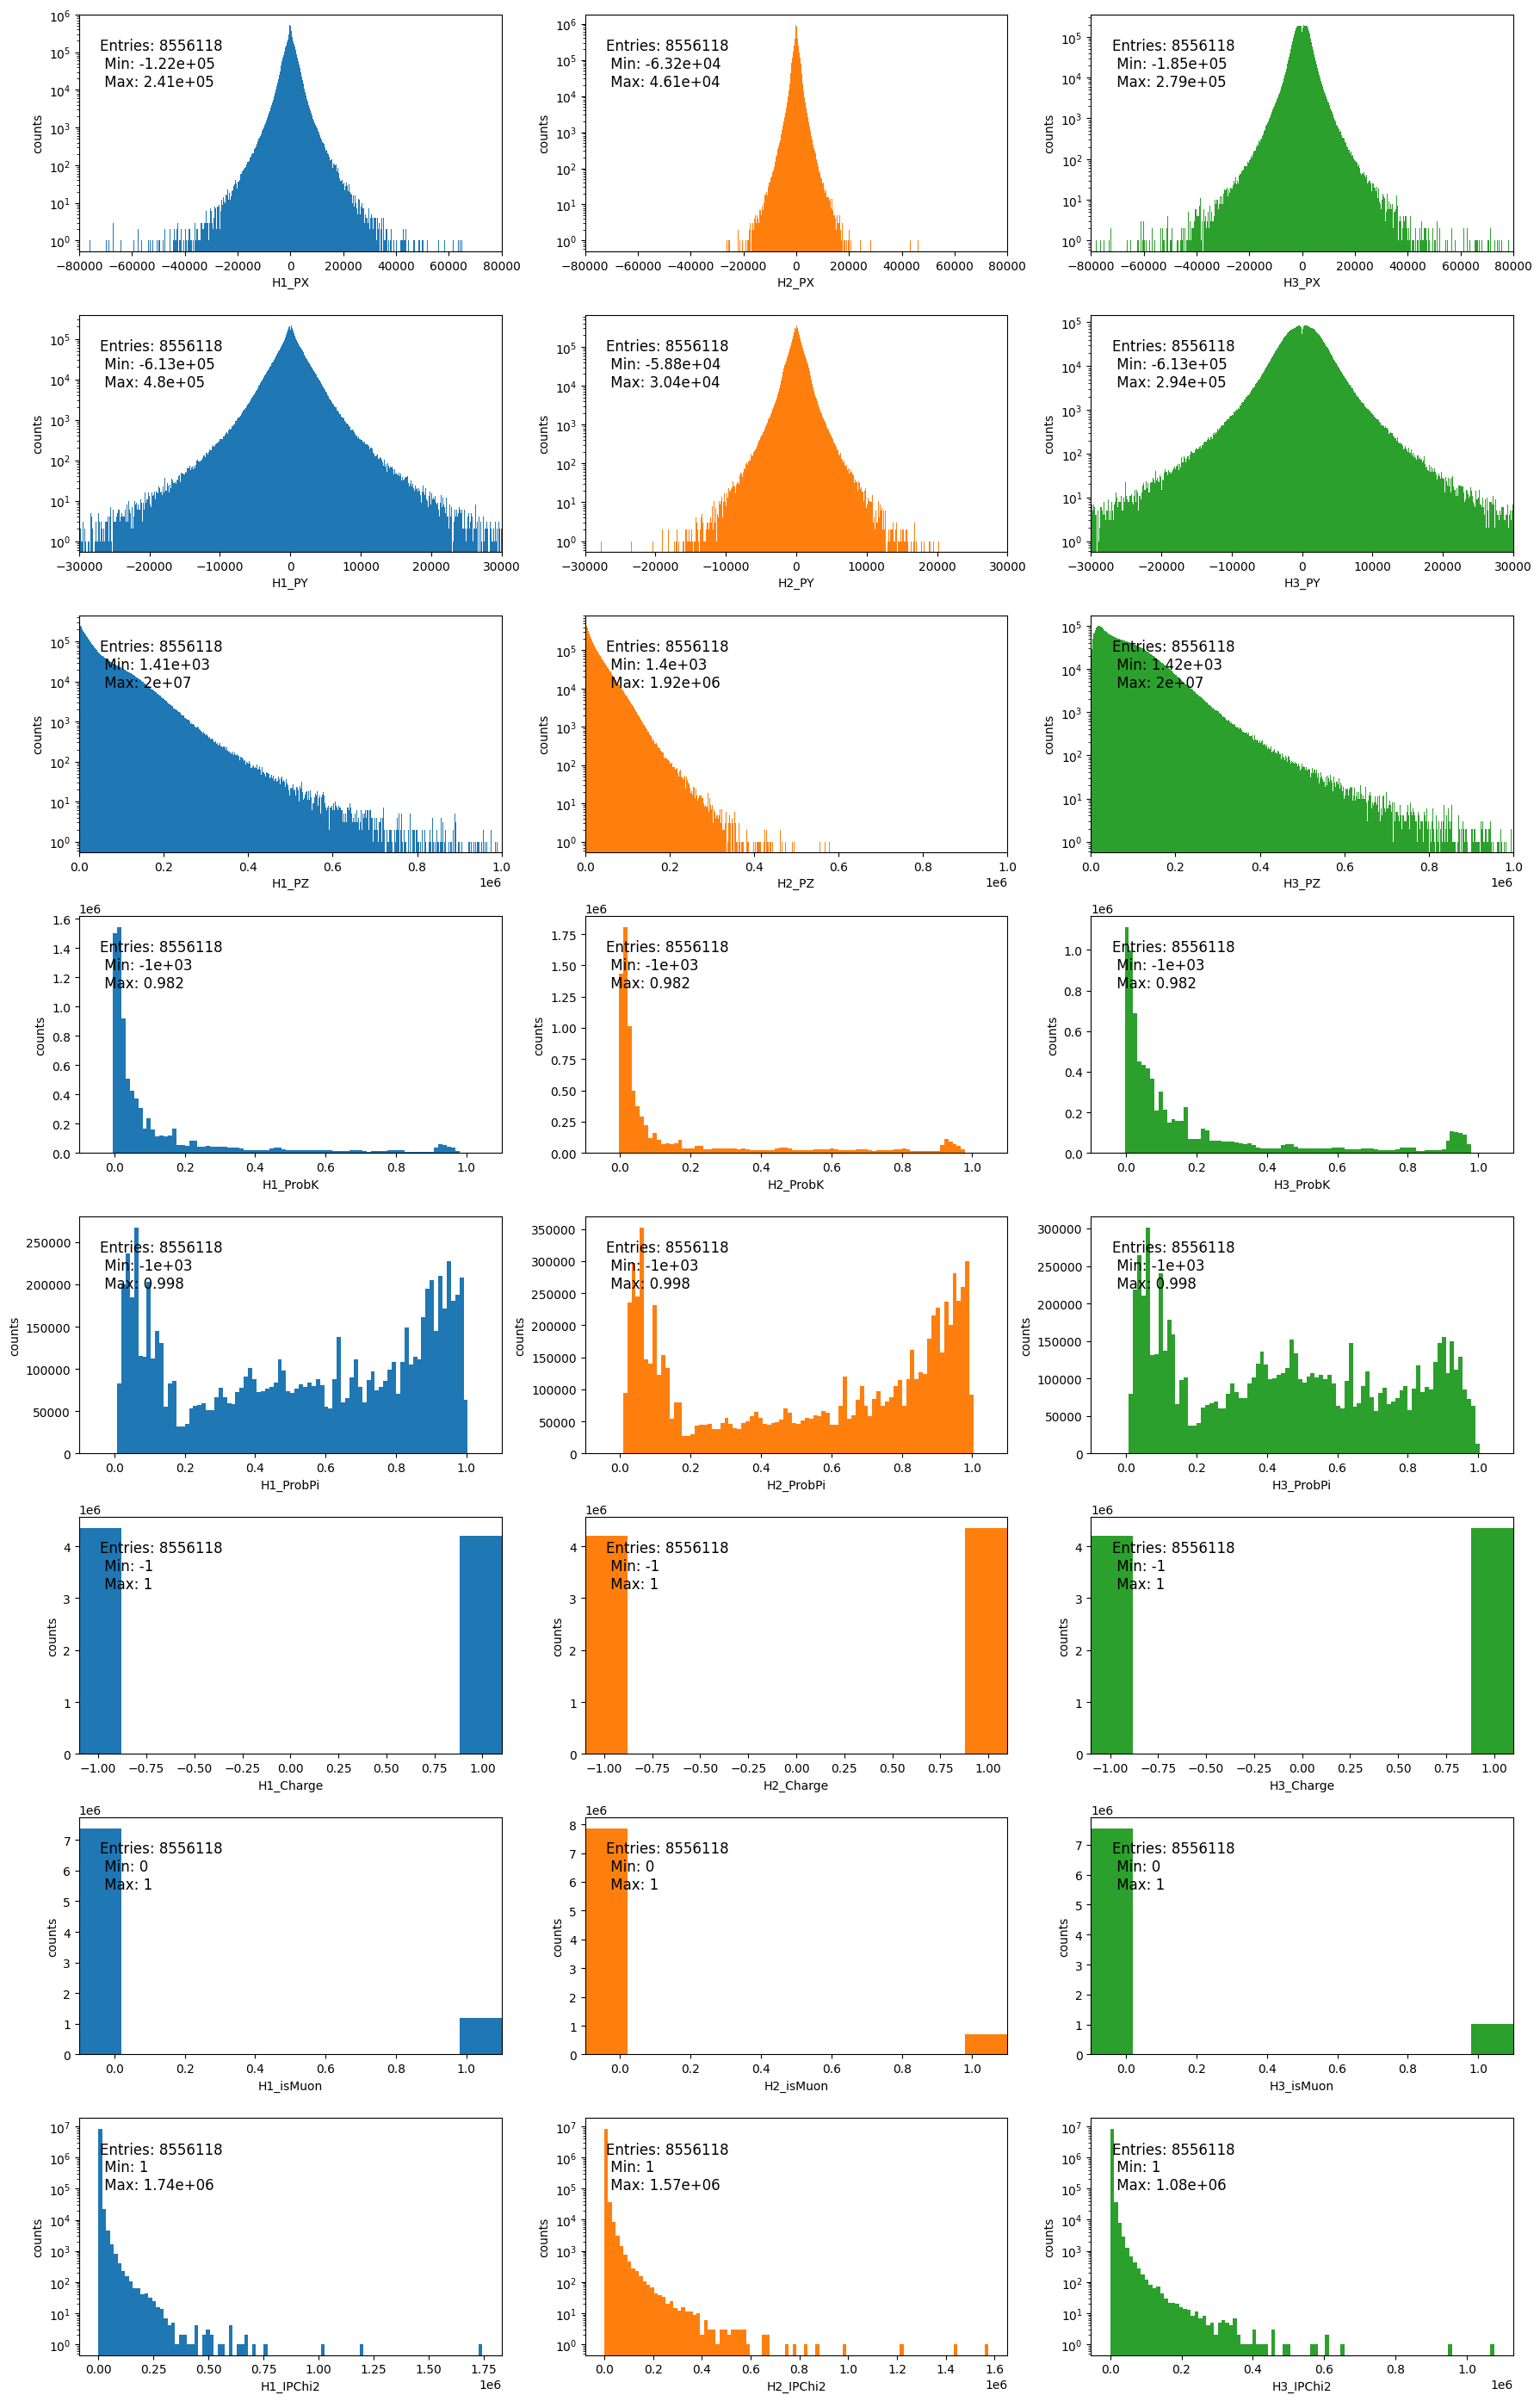

In [10]:
figs = lf.plot_all_features(all_data, lf.GLOBAL_FEATURES, lf.PRODUCT_FEATURES + lf.EXTRA_PRODUCT_FEATURES,
                            lf.PLOT_SETTINGS["raw"], cfg.n_products)

In [11]:
# keep only the columns needed by the analysis
data = all_data[cfg.columns].copy()
del all_data
print(data.columns.tolist())

['H1_PX', 'H1_PY', 'H1_PZ', 'H1_ProbK', 'H1_ProbPi', 'H1_Charge', 'H1_isMuon', 'H2_PX', 'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi', 'H2_Charge', 'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK', 'H3_ProbPi', 'H3_Charge', 'H3_isMuon', 'magnet']


### Preselection (B -> KKK)

preselection efficiency: 0.28%


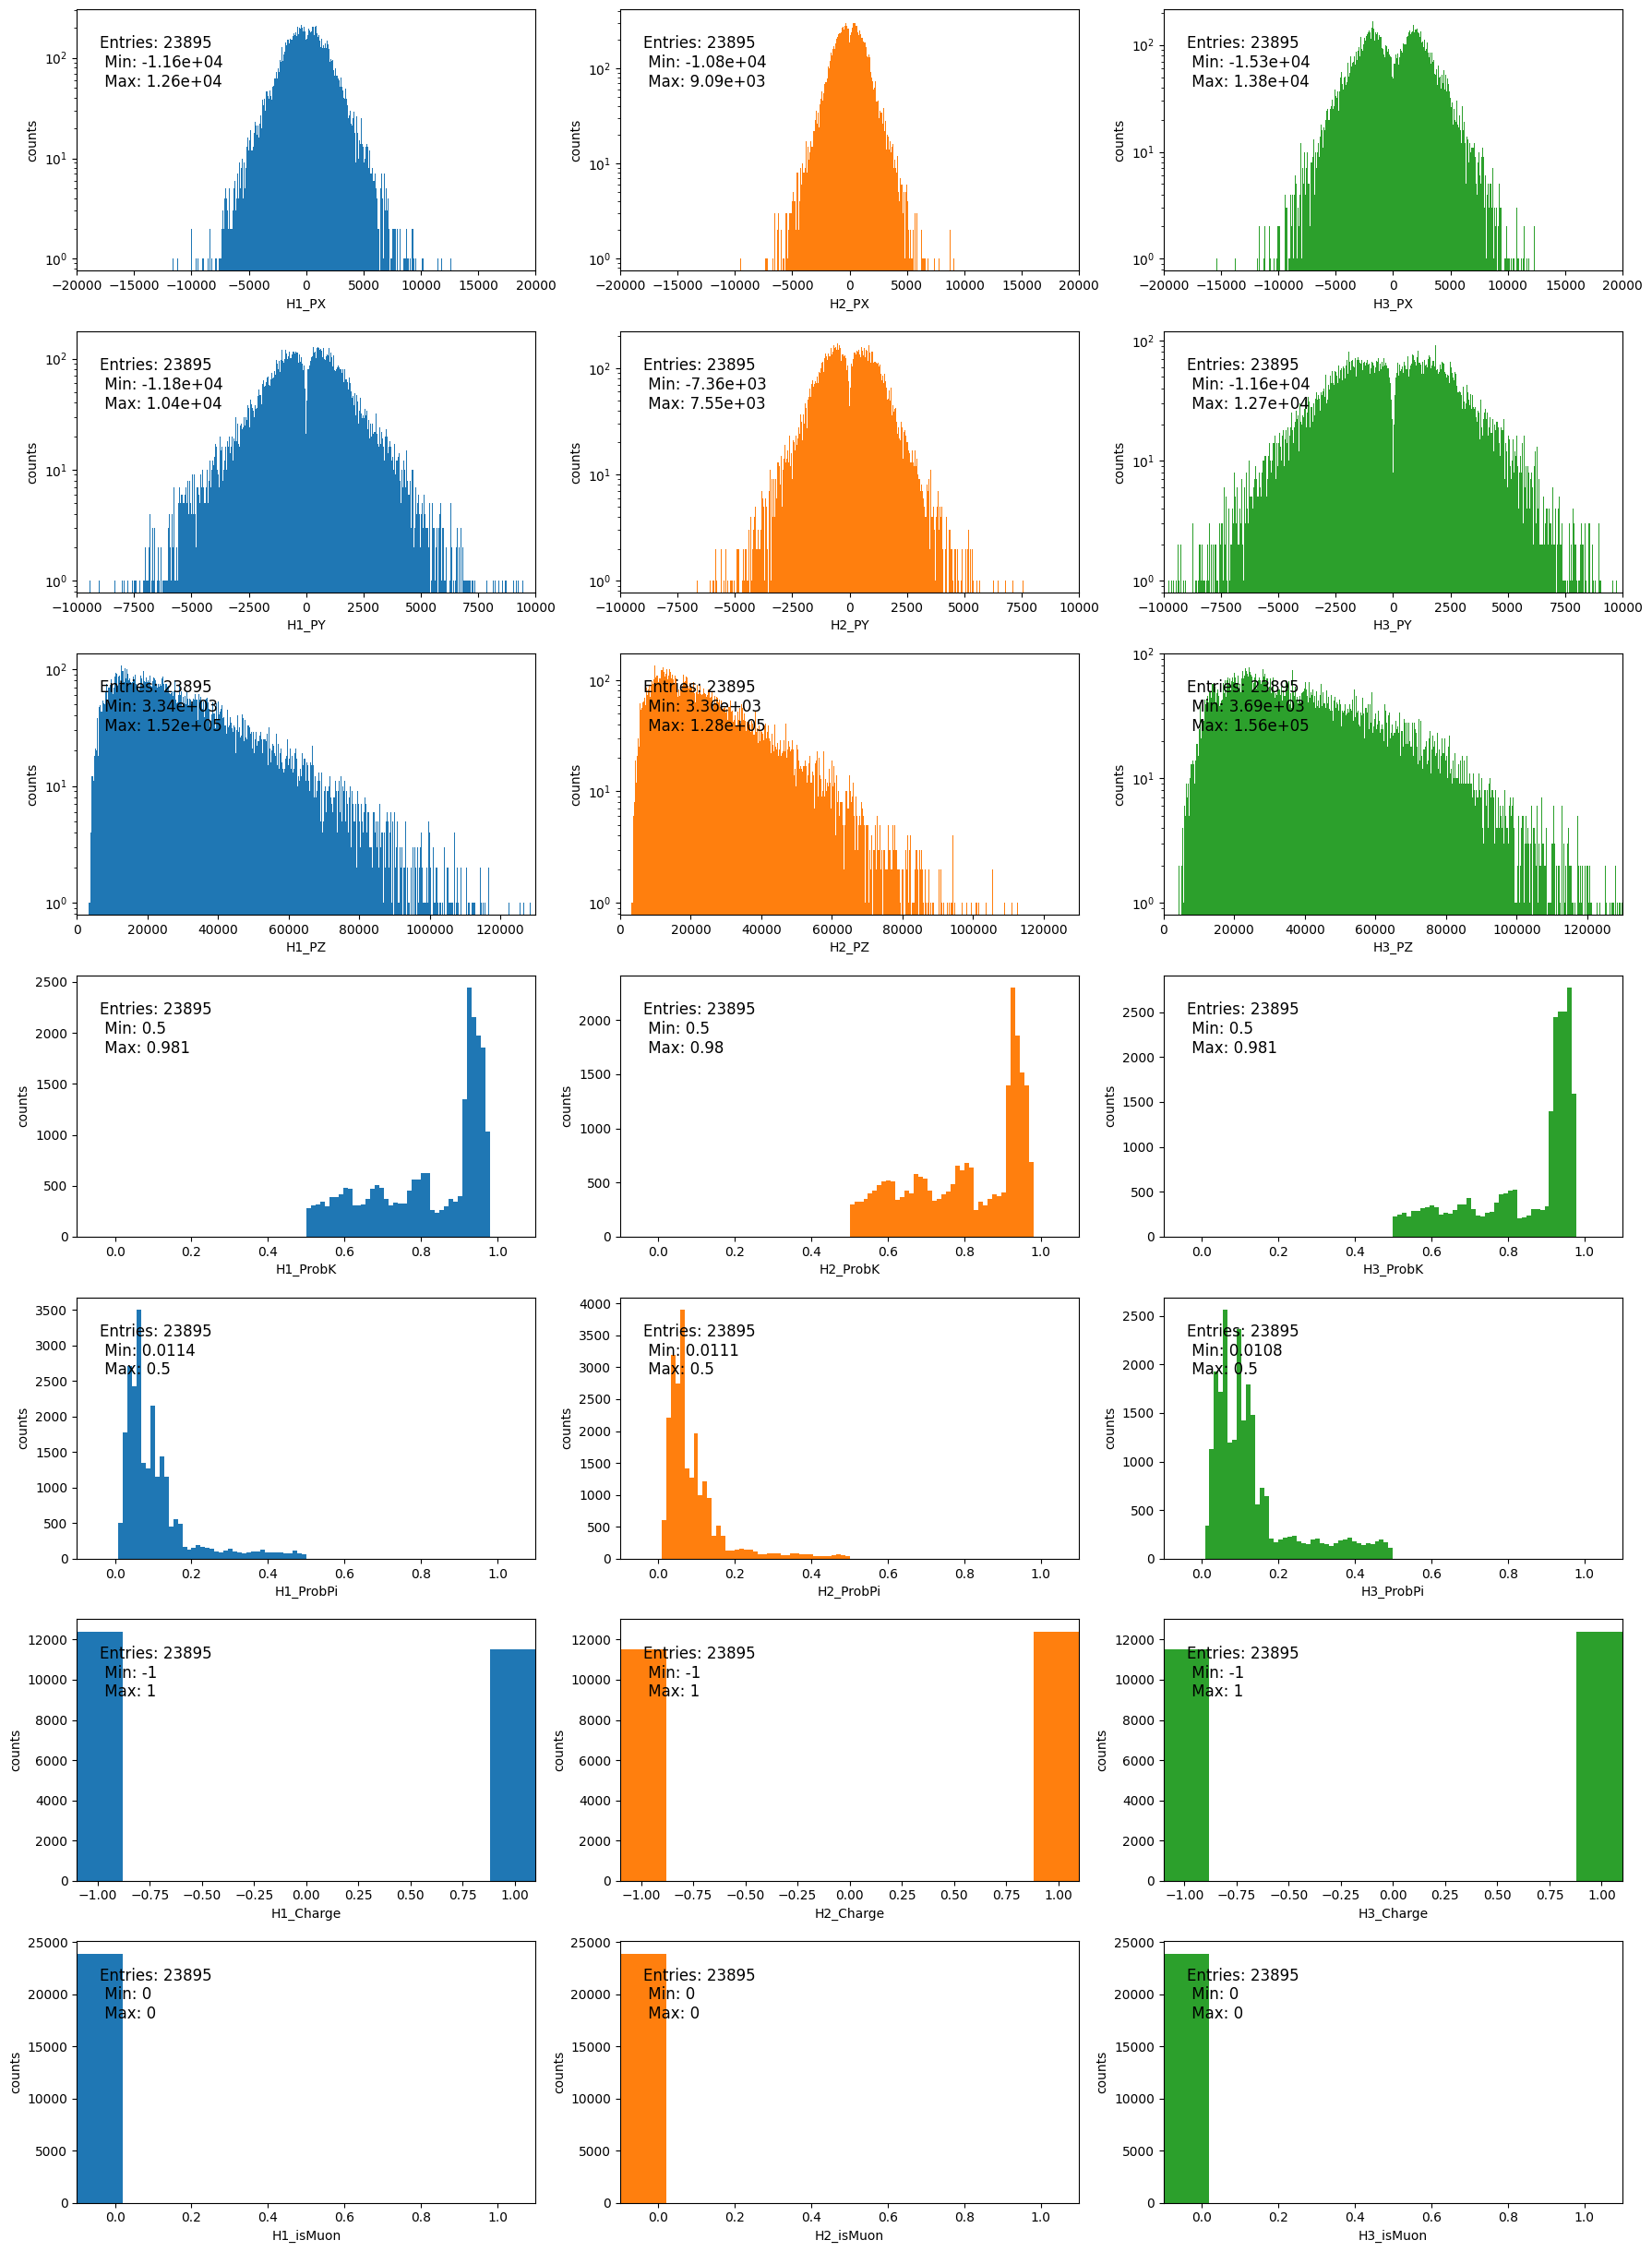

In [12]:
presel_kaon = lf.kaon_preselection(data, cfg)     # boolean mask: 3 kaons, no pions, no muons
print(f"preselection efficiency: {presel_kaon.mean():.2%}")
figs = lf.plot_all_features(data[presel_kaon], product_features=lf.PRODUCT_FEATURES,
                            settings=lf.PLOT_SETTINGS["presel"], n_products=cfg.n_products)

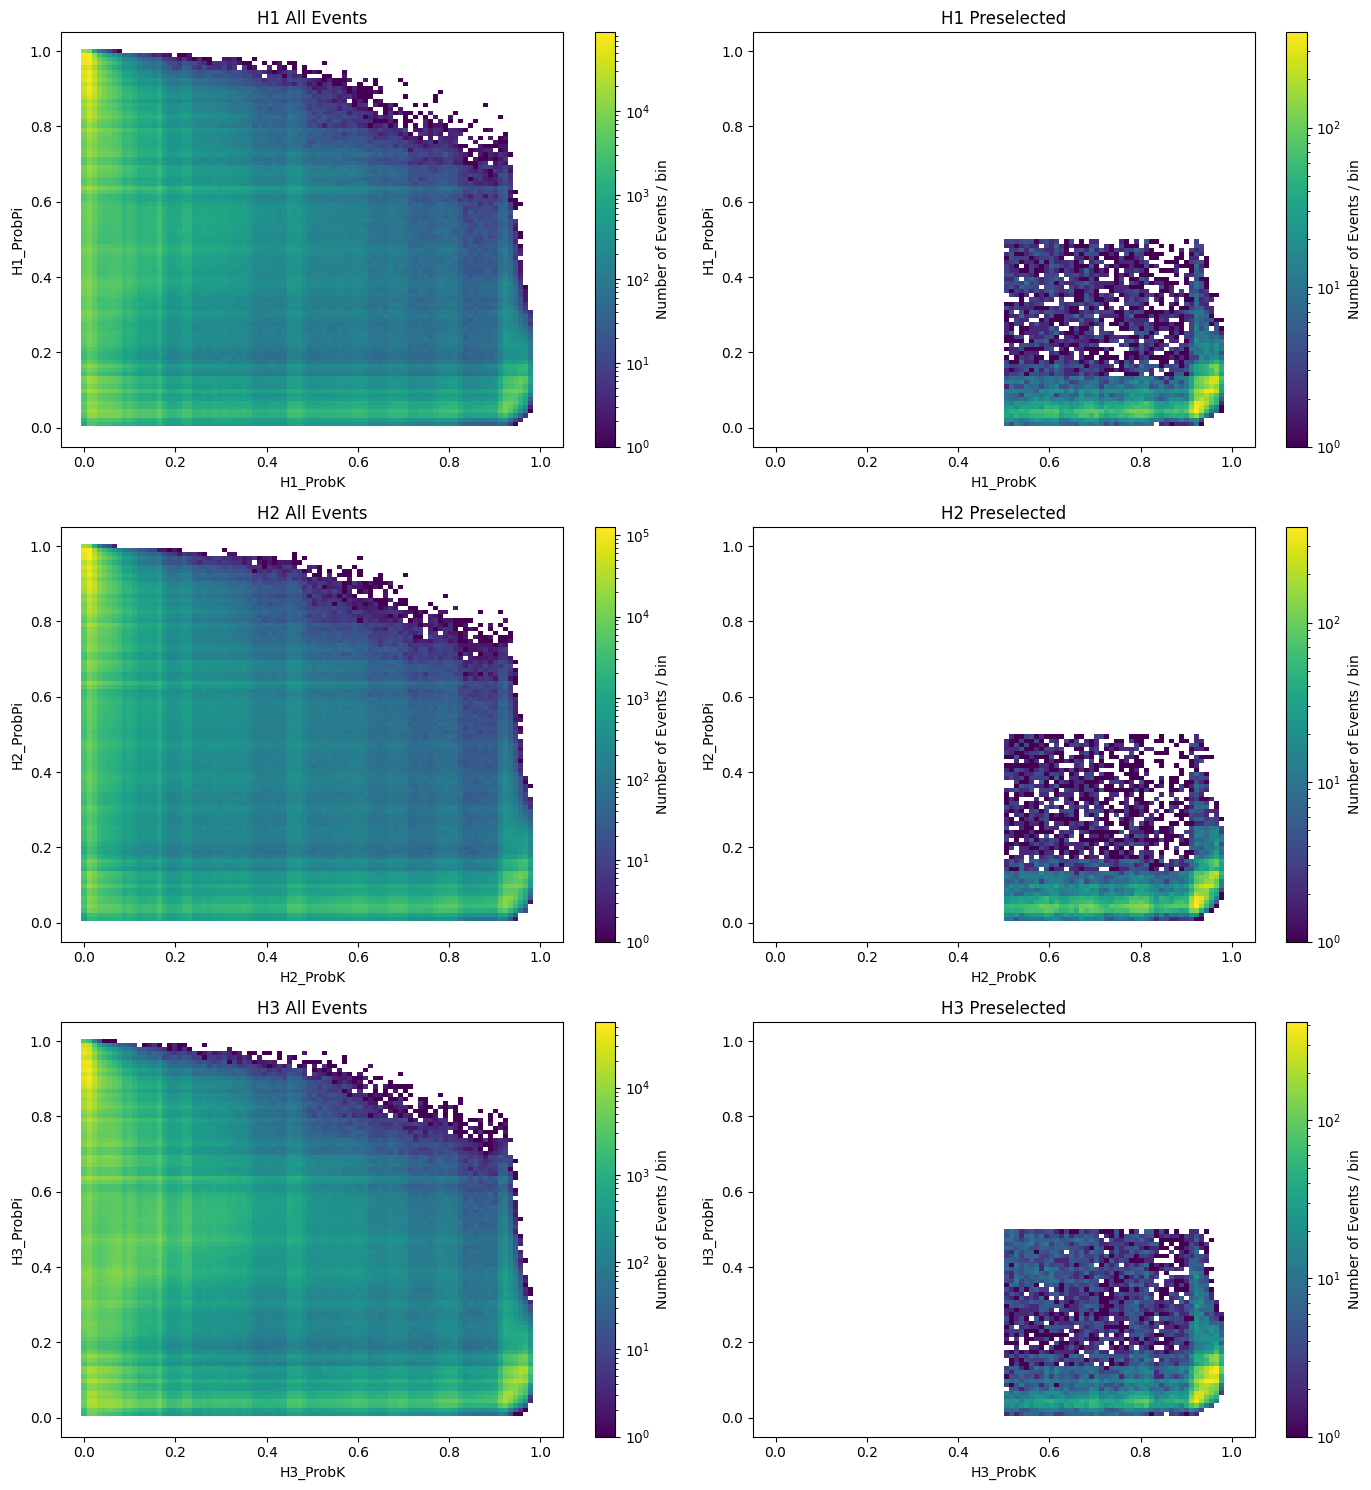

In [13]:
# 2D plot of ProbK vs ProbPi, before / after the preselection
lf.plot_pid_2d(data, data[presel_kaon], cfg);

### Preselection (B -> πππ)

preselection efficiency: 12.33%


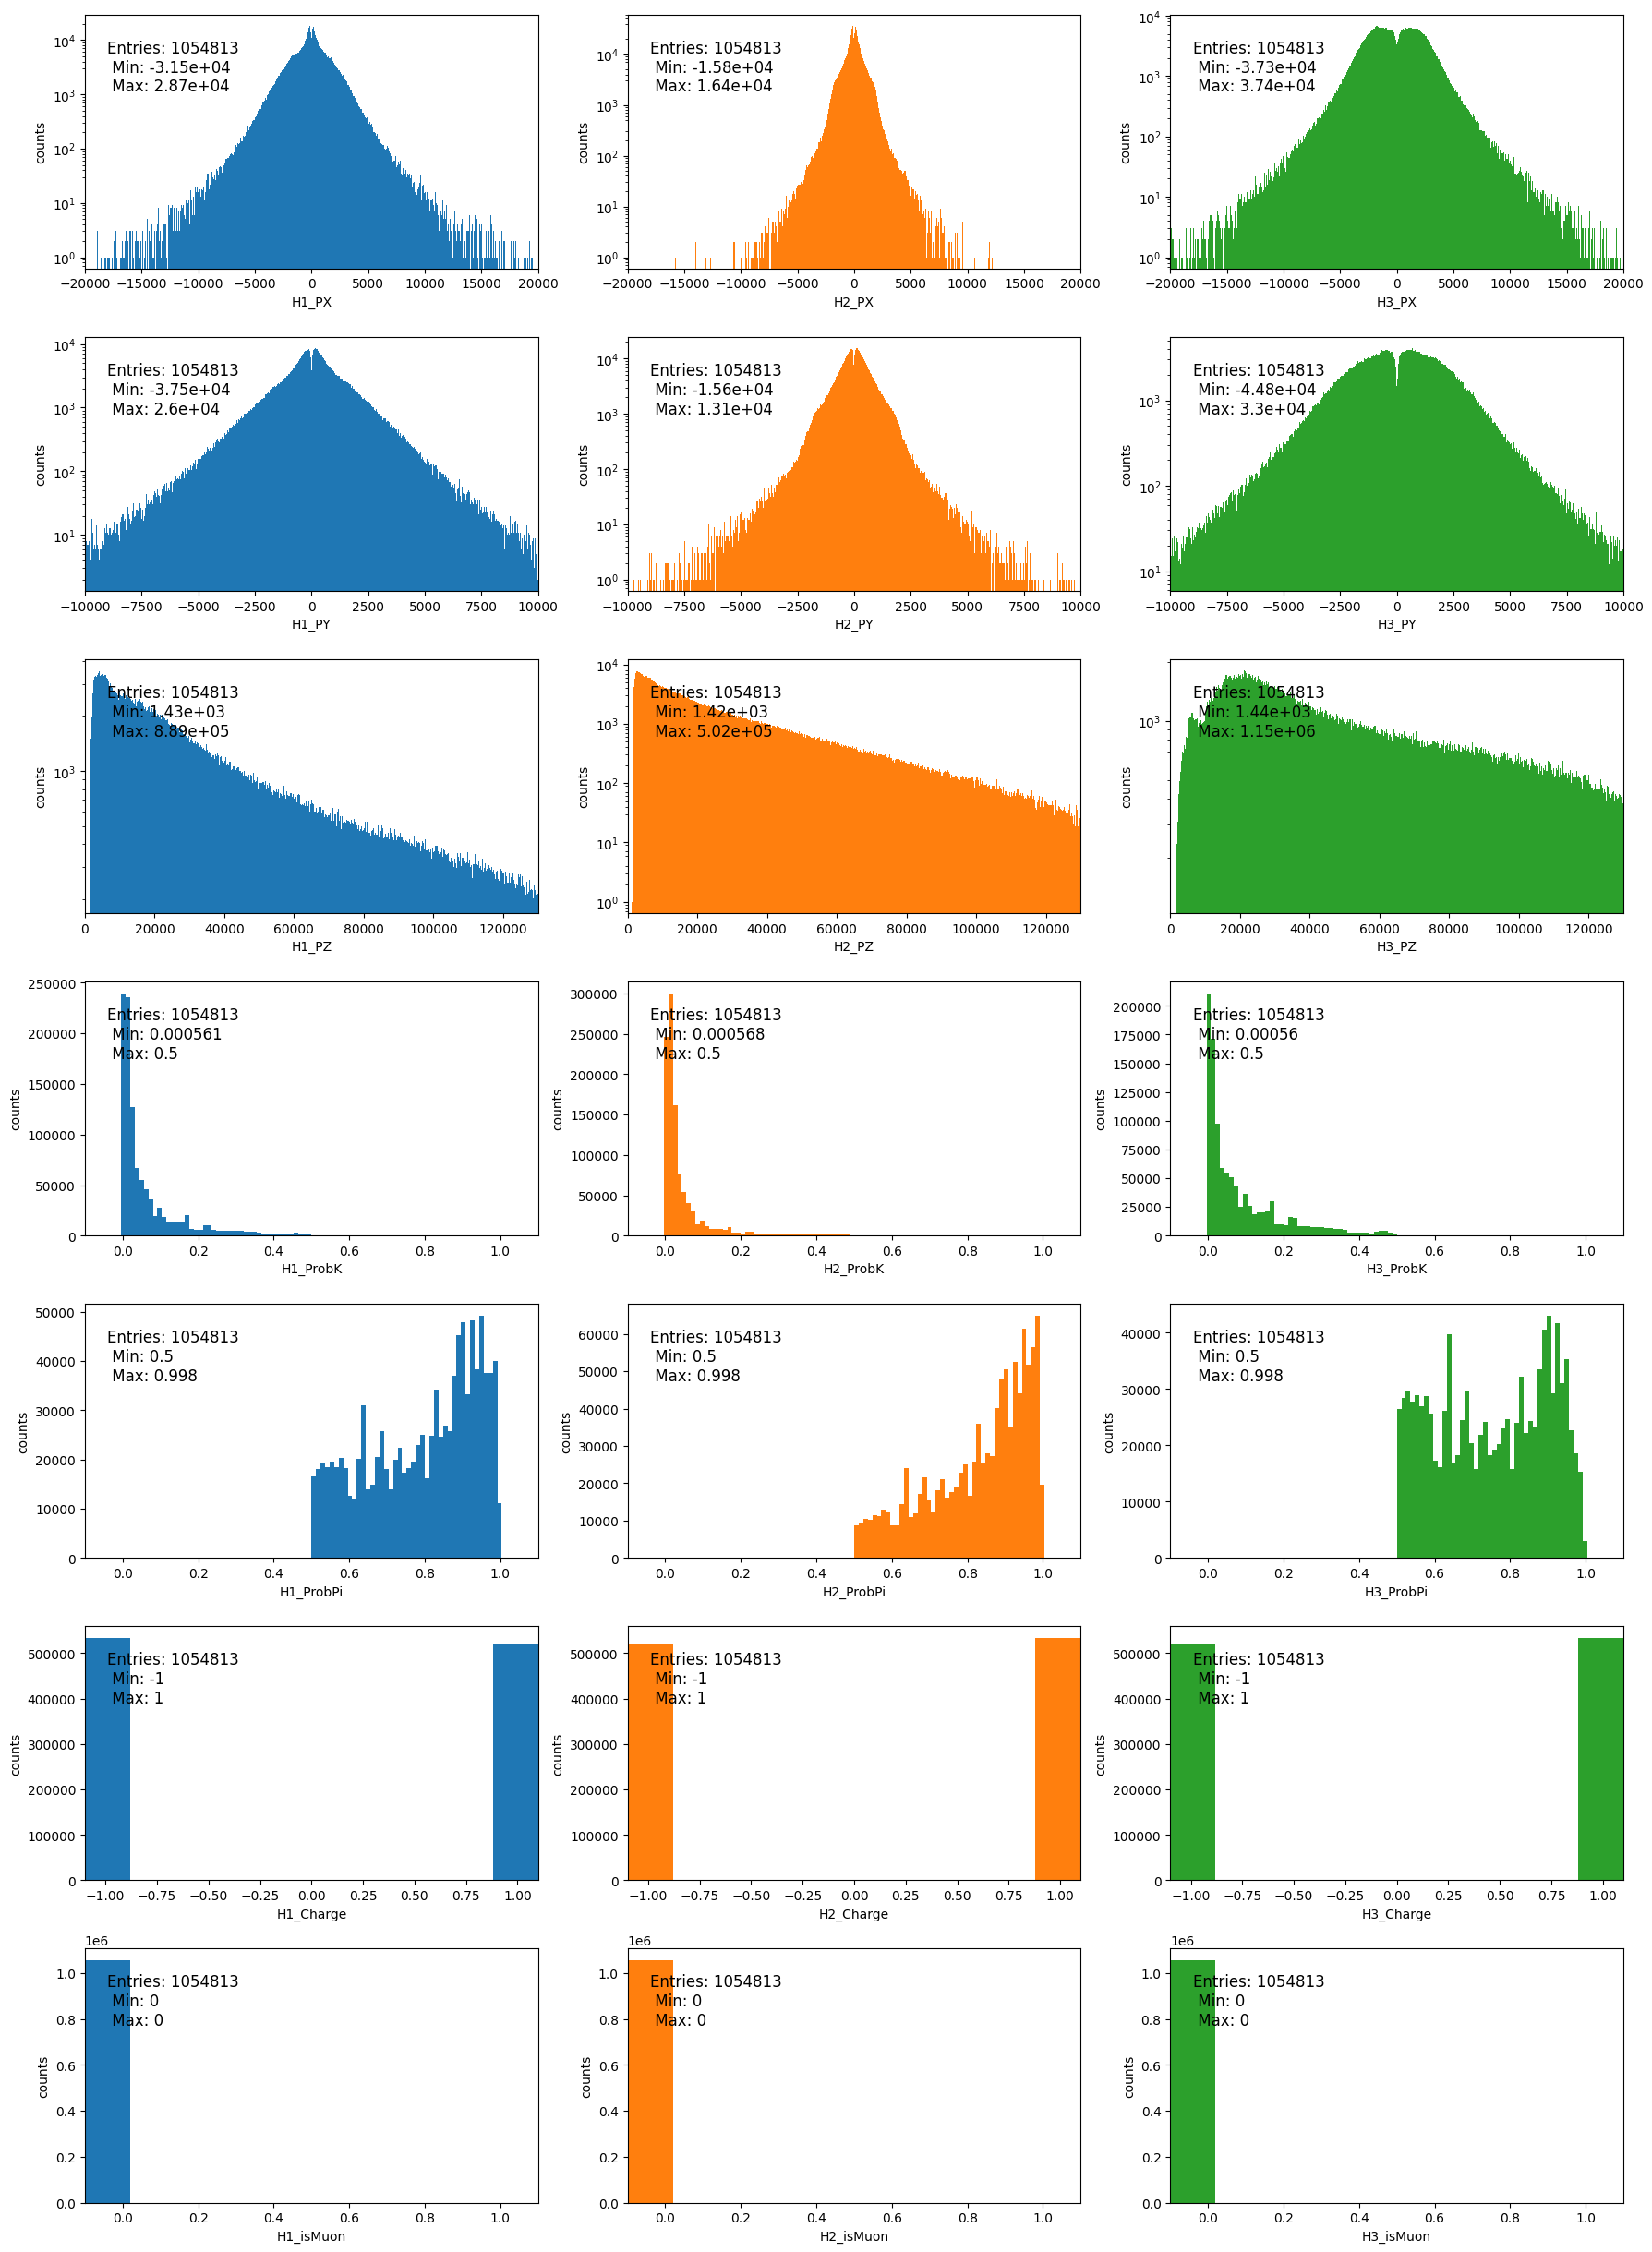

In [14]:
presel_pion = lf.pion_preselection(data, cfg)     # boolean mask: no kaons, 3 pions, no muons
print(f"preselection efficiency: {presel_pion.mean():.2%}")
figs = lf.plot_all_features(data[presel_pion], product_features=lf.PRODUCT_FEATURES,
                            settings=lf.PLOT_SETTINGS["presel"], n_products=cfg.n_products)

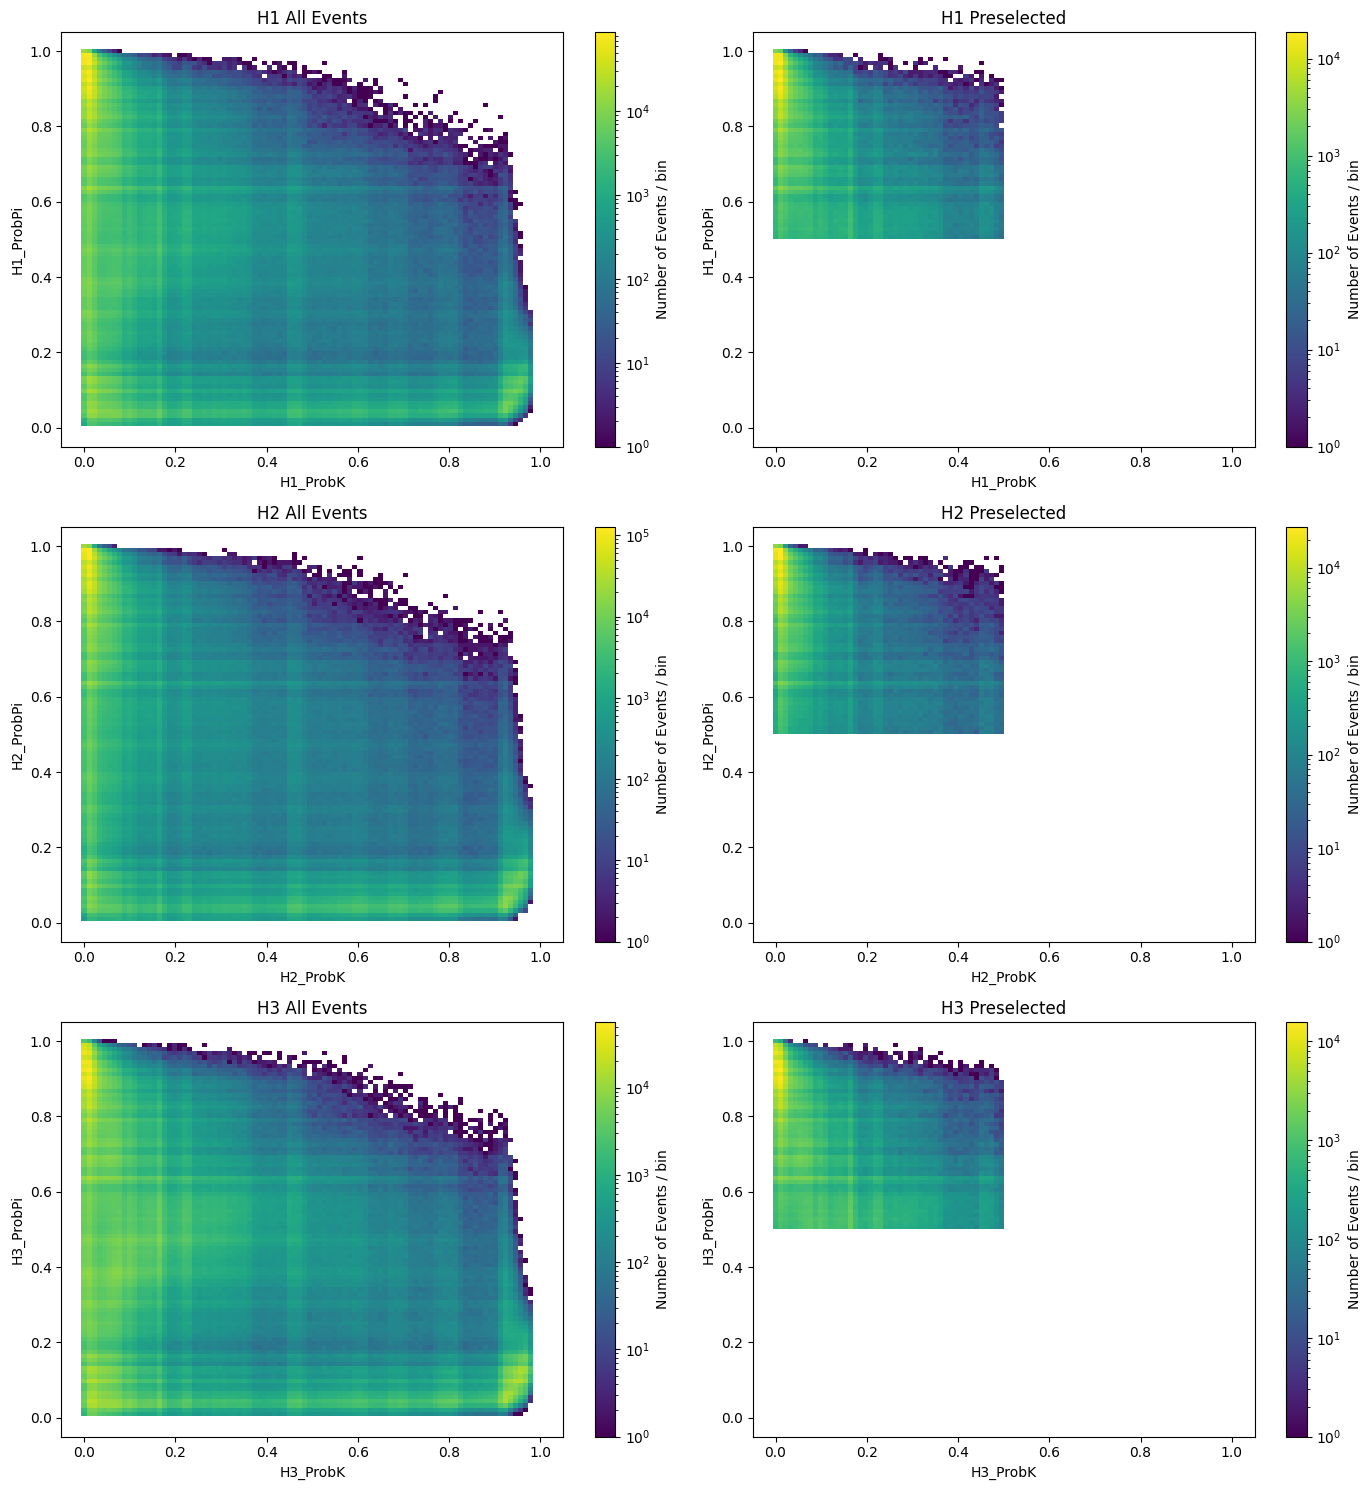

In [15]:
# 2D plot of ProbK vs ProbPi, before / after the preselection
lf.plot_pid_2d(data, data[presel_pion], cfg);

In [16]:
data_pion = data[presel_pion].reset_index(drop=True)

### Compute Invariant Mass

In [17]:
data = data[presel_kaon].reset_index(drop=True)
lf.add_B_variables(data, cfg)        # B_Mass and B_Charge (= sum of the product charges)
lf.check_charges(data, cfg)          # all charges must be +-1
print(data["B_Charge"].value_counts())

H1_Charge: [-1  1]
H2_Charge: [-1  1]
H3_Charge: [-1  1]
B_Charge
 1    12390
-1    11505
Name: count, dtype: int64


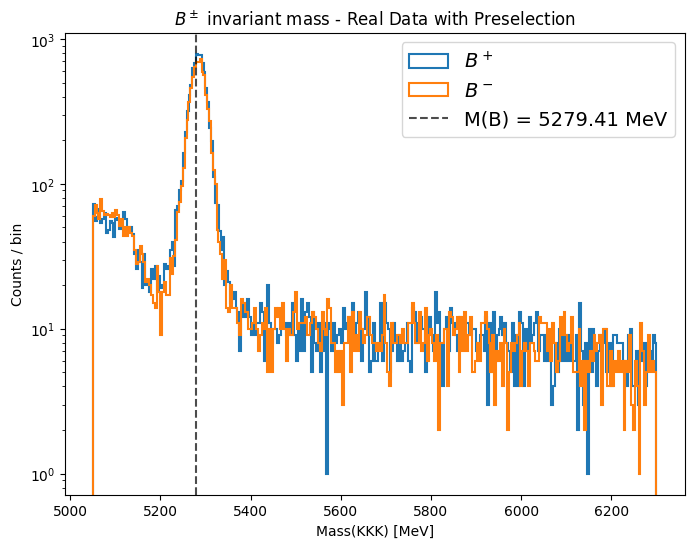

In [18]:
lf.plot_mass_by_charge(data, cfg, bins=300, logy=True, title=r"$B^\pm$ invariant mass - Real Data with Preselection");

events in fit window [5100.0, 5600.0] MeV: 19731
  B+ : 10292   B- : 9439  -->  raw A_CP = -0.043231 ± 0.007112
  magnet down: 11636   magnet up: 8095


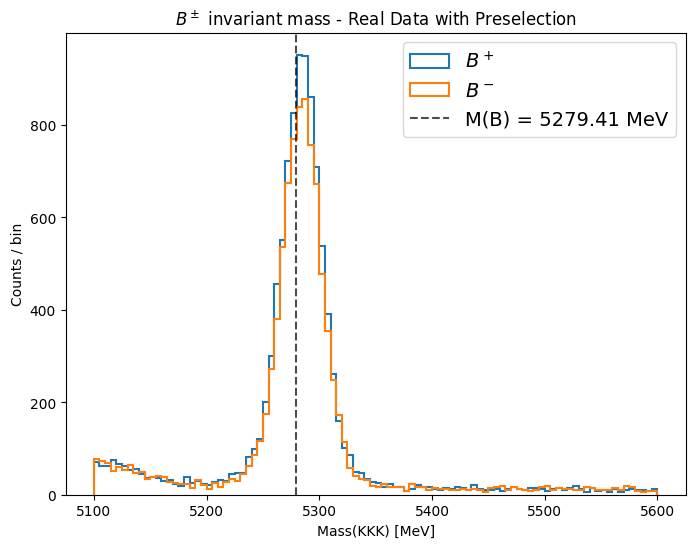

In [19]:
# cut the data in the fit window and split in B+ / B-
data_window = lf.select_window(data, cfg.fit_window)
samples = lf.split_by_charge(data_window, col='B_Mass')       # {'pos': B+ masses, 'neg': B- masses}

lf.plot_mass_by_charge(data_window, cfg, bins=100, bin_range=cfg.fit_window,
                       title=r"$B^\pm$ invariant mass - Real Data with Preselection")
lf.print_event_summary(data_window, cfg)

## Frequentist fit

Conventions (see `lhcb_freq.py`): the model is *extended* (signal yield and background yield are fit parameters),
signal = Gaussian, background = 1 or 2 exponentials (`cfg.n_exp`), both normalised in `cfg.fit_window`.
`A_CP = (N(B-) - N(B+)) / (N(B-) + N(B+))`.

### Sideband

Events in sideband (B+ / B-): 1530 / 1516 | total: 19731
Sideband pos
lam1       -> 0.025433 ± 0.004433
lam2       -> 0.001827 ± 0.000467
f_bkgs     -> 0.276517 ± 0.047763
Sideband neg
lam1       -> 0.024230 ± 0.003569
lam2       -> 0.001090 ± 0.000504
f_bkgs     -> 0.326013 ± 0.043662


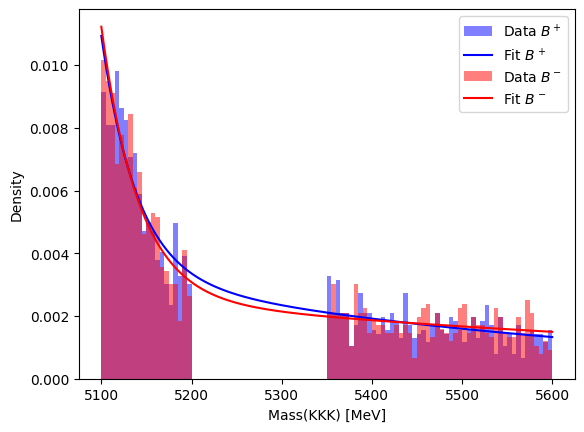

In [73]:
# Sideband = fit window without the signal region
sb_samples = {s: lf.select_sideband(m, cfg) for s, m in samples.items()}
print("Events in sideband (B+ / B-):", len(sb_samples["pos"]), "/", len(sb_samples["neg"]), "| total:", len(data_window))

sb_fits = {s: lf.fit_sideband(m, cfg) for s, m in sb_samples.items()}
for s, f in sb_fits.items():
    print(f"Sideband {s}")
    lf.print_params(f)
lf.plot_sideband(sb_samples, sb_fits, cfg);

In [74]:
# Background expected in the signal region (extrapolated from the sideband) vs observed events
for s, m in samples.items():
    b = lf.expected_background_in_signal(sb_fits[s], len(sb_samples[s]), cfg)
    print(f"{s}: expected background b = {b:.1f},  observed N_obs = {lf.in_region(m, cfg.sig_region).sum()}")

pos: expected background b = 544.5,  observed N_obs = 8762
neg: expected background b = 492.2,  observed N_obs = 7923


### Separate fits (B+ and B-)

In [75]:
sep_fits = {s: lf.fit_single(m, cfg) for s, m in samples.items()}
for s, f in sep_fits.items():
    print(s, "valid:", f.valid)
    display(f)
a, da = lf.asymmetry_from_yields(sep_fits)
print(f"A_CP (separate fits) = {a:.4f} ± {da:.4f}")

pos valid: True


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -6.536e+04                 │              Nfcn = 262              │
│ EDM = 8.45e-07 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig  │   8.0e3   │   0.1e3   │            │            │    0    │         │       │
│ 1 │ mu     │ 5.28429e3 │ 0.00022e3 │            │            │  5200   │  5350   │       │
│ 2 │ sigma  │   18.0    │    0.2    │            │            │    1    │   100   │       │
│ 3 │ N_bkg  │  2.29e3   │  0.06e3   │            │            │    0    │         │       │
│ 4 │ lam1   │   0.035   │   0.008   │            │            │  1e-06  │    1    │       │
│ 5 │ lam2   │  2.81e-3  │  0.28e-3  │            │            │  1e-06  │    1    │       │
│ 6 │ f_bkgs │   0.113   │   0.028   │            │            │    0    │    1    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬─────────────────────────────────────────────────────────────────────────────────────┐
│        │       N_sig          mu       sigma       N_bkg        lam1        lam2      f_bkgs │
├────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│  N_sig │    9.19e+03       -0.59        3.65      -1.2e3  -111.99e-3 -5.02216e-3    590.2e-3 │
│     mu │       -0.59       0.049       -0.00        0.59     0.06e-3     5.23e-6     -0.4e-3 │
│  sigma │        3.65       -0.00      0.0388       -3.65    -0.32e-3   -15.10e-6      1.8e-3 │
│  N_bkg │      -1.2e3        0.59       -3.65    3.48e+03   111.99e-3  5.02226e-3   -590.2e-3 │
│   lam1 │  -111.99e-3     0.06e-3    -0.32e-3   111.99e-3    5.84e-05     1.31e-6    -0.16e-3 │
│   lam2 │ -5.02216e-3     5.23e-6   -15.10e-6  5.02226e-3     1.31e-6    8.09e-08    -6.32e-6 │
│ f_bkgs │    590.2e-3     -0.4e-3      1.8e-3   -590.2e-3    -0.16e-3    -6.32e-6    0.000783 │
└────────┴─────────────────────────────────────────────────────────────────────────────────────┘

neg valid: True


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -5.799e+04                 │              Nfcn = 226              │
│ EDM = 5.05e-05 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig  │  7.33e3   │  0.09e3   │            │            │    0    │         │       │
│ 1 │ mu     │ 5.28447e3 │ 0.00023e3 │            │            │  5200   │  5350   │       │
│ 2 │ sigma  │   18.0    │    0.2    │            │            │    1    │   100   │       │
│ 3 │ N_bkg  │  2.11e3   │  0.06e3   │            │            │    0    │         │       │
│ 4 │ lam1   │   0.028   │   0.005   │            │            │  1e-06  │    1    │       │
│ 5 │ lam2   │  1.6e-3   │  0.4e-3   │            │            │  1e-06  │    1    │       │
│ 6 │ f_bkgs │   0.21    │   0.04    │            │            │    0    │    1    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬─────────────────────────────────────────────────────────────────────────────────────┐
│        │       N_sig          mu       sigma       N_bkg        lam1        lam2      f_bkgs │
├────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│  N_sig │    8.46e+03       -0.40        3.59      -1.1e3  -76.319e-3 -9.00929e-3      0.9240 │
│     mu │       -0.40      0.0524       -0.00        0.40   -0.009e-3     4.12e-6     -0.0002 │
│  sigma │        3.59       -0.00      0.0403       -3.59   -0.218e-3   -27.16e-6      0.0028 │
│  N_bkg │      -1.1e3        0.40       -3.59    3.25e+03   76.322e-3  9.00965e-3     -0.9241 │
│   lam1 │  -76.319e-3   -0.009e-3   -0.218e-3   76.322e-3    2.24e-05     1.41e-6   -0.157e-3 │
│   lam2 │ -9.00929e-3     4.12e-6   -27.16e-6  9.00965e-3     1.41e-6    1.68e-07   -14.41e-6 │
│ f_bkgs │      0.9240     -0.0002      0.0028     -0.9241   -0.157e-3   -14.41e-6      0.0016 │
└────────┴─────────────────────────────────────────────────────────────────────────────────────┘

A_CP (separate fits) = -0.0442 ± 0.0087


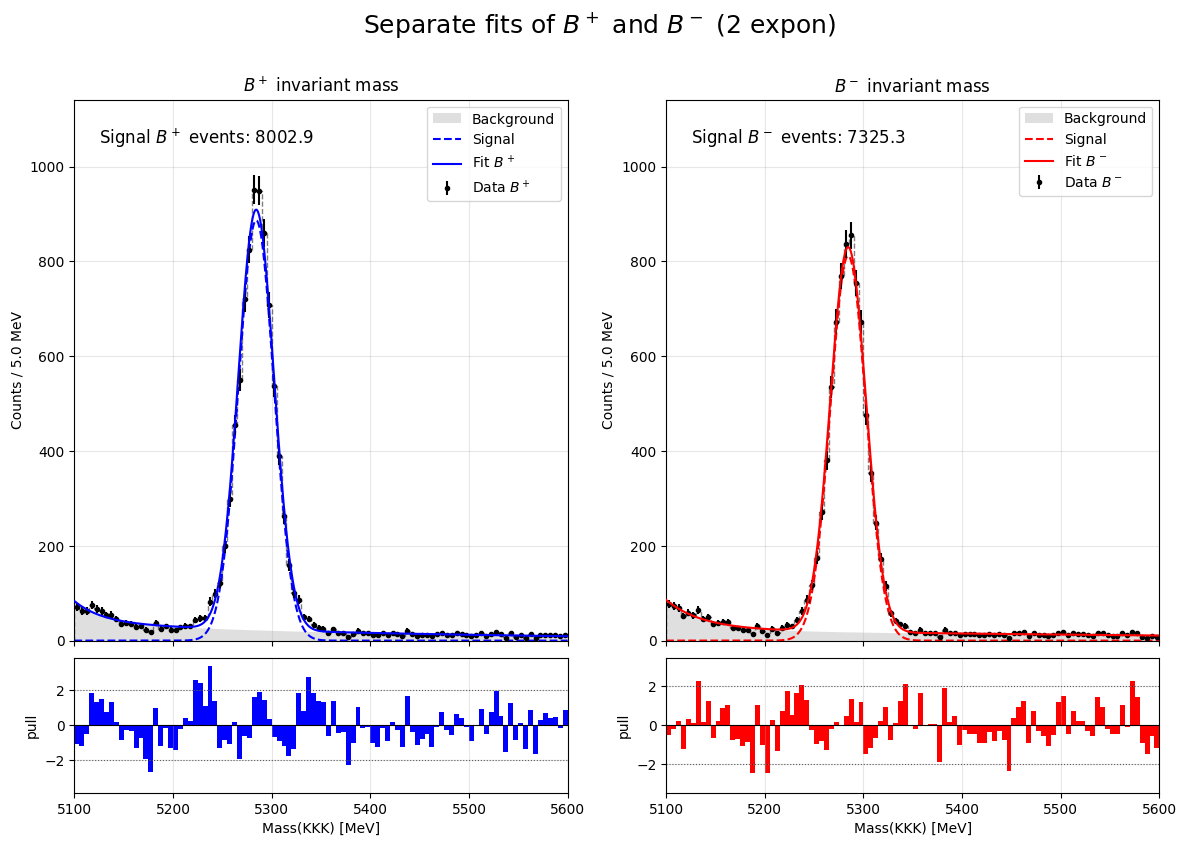

In [76]:
lf.plot_separate_fits(sep_fits, samples, cfg);

#### Goodness of fit ($\chi^2$)

In [93]:
for s, m in samples.items():
    f = sep_fits[s]
    print(f"--- {s}")
    print(lf.chi2_gof(m, lf.fitted_curve(f, cfg), cfg.fit_window, bins=100, n_free=f.nfit))

--- pos
Chi2:         142.58
NDOF:         93
Chi2 / NDOF:  1.533
p-value:      0.0007258668884955762
--- neg
Chi2:         110.31
NDOF:         93
Chi2 / NDOF:  1.186
p-value:      0.10632587949068621


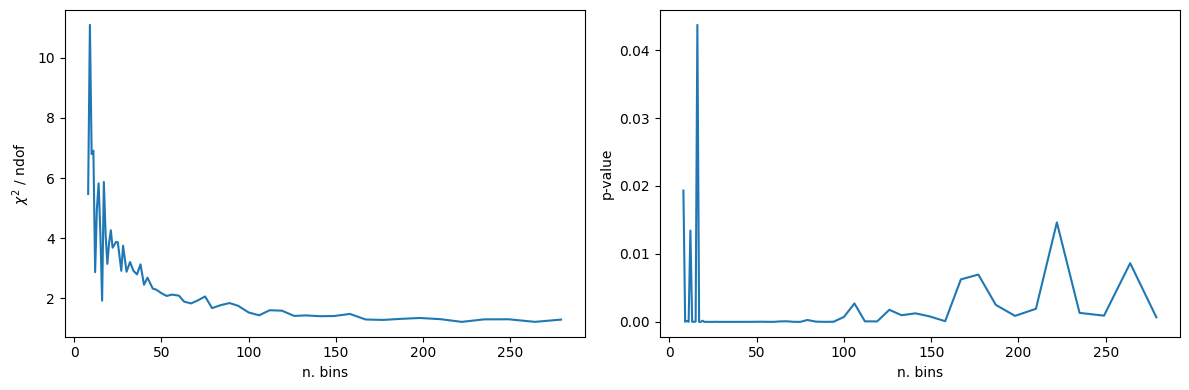

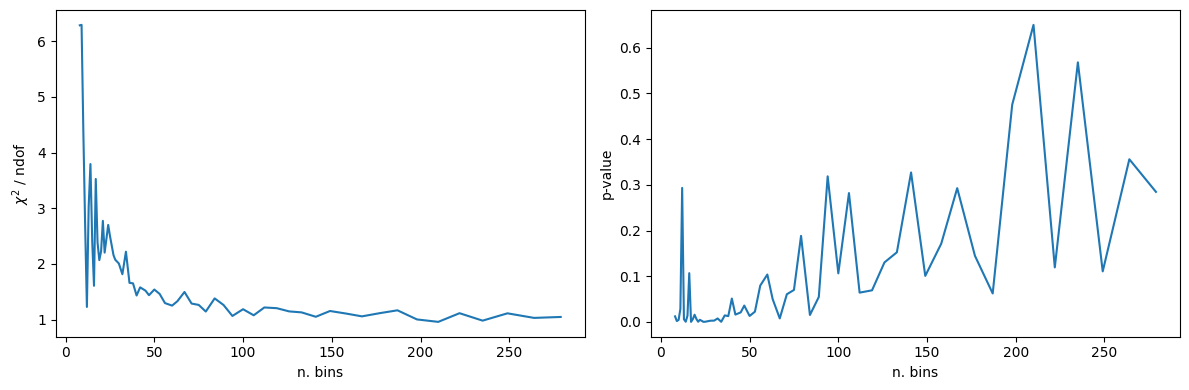

In [25]:
# chi2/ndof and p-value as a function of the number of bins (B+)
bin_values = np.unique(np.logspace(0, 3.5, 100, base=5).astype(int))
f = sep_fits["pos"]
chi2_red, p_vals = lf.scan_gof_bins(samples["pos"], lf.fitted_curve(f, cfg), cfg.fit_window, f.nfit, bin_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(bin_values, chi2_red); axes[0].set(xlabel="n. bins", ylabel=r"$\chi^2$ / ndof")
axes[1].plot(bin_values, p_vals);   axes[1].set(xlabel="n. bins", ylabel="p-value")
fig.tight_layout()

# chi2/ndof and p-value as a function of the number of bins (B-)
bin_values = np.unique(np.logspace(0, 3.5, 100, base=5).astype(int))
f = sep_fits["neg"]
chi2_red, p_vals = lf.scan_gof_bins(samples["neg"], lf.fitted_curve(f, cfg), cfg.fit_window, f.nfit, bin_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(bin_values, chi2_red); axes[0].set(xlabel="n. bins", ylabel=r"$\chi^2$ / ndof")
axes[1].plot(bin_values, p_vals);   axes[1].set(xlabel="n. bins", ylabel="p-value")
fig.tight_layout()

### Joint Fit

I want to do a joint fot for the B+ and B- peaks. 

The common parameters are:

- mu:    B+/B- mass, the same = 5279.15 MeV
- sigma: resolution, the same for B+/B- because the detector is symmetric
- N_sig: signal events (B+ and B-)
- A_CP:  CP asymmetry (N_sig_neg - N_sig_pos) / (N_sig_neg + N_sig_pos)

Specific parameters:

- For B+
    - N_bkg_pos:  events of bkgs
    - lam1_pos:   bkg1
    - lam2_pos:   bkg2
    - f_bkgs_pos: fraction of contribution bkg1 respect bkg2

- For B-
    - N_bkg_neg:  events of bkgs
    - lam1_neg:   bkg1
    - lam2_neg:   bkg2
    - f_bkgs_neg: fraction of contribution bkg1 respect bkg2

In [101]:
# 2 exponentials (default) and 1 exponential (simpler background model)
joint = {n: lf.fit_joint(samples, cfg, n_exp=n, minos=True) for n in (2, 1)}
display(joint[1])
display(joint[2])

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -1.232e+05                 │              Nfcn = 858              │
│ EDM = 6.33e-06 (Goal: 0.0002)    │            time = 1.5 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name      │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig     │  15.08e3  │  0.13e3   │  -0.13e3   │   0.13e3   │    0    │         │       │
│ 1 │ A_CP      │  -0.048   │   0.008   │   -0.008   │   0.008    │   -1    │    1    │       │
│ 2 │ mu        │ 5.28449e3 │ 0.00016e3 │ -0.00016e3 │ 0.00016e3  │  5200   │  5350   │       │
│ 3 │ sigma     │   17.64   │   0.13    │   -0.13    │    0.13    │    1    │   100   │       │
│ 4 │ N_bkg_pos │  2.39e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 5 │ lam1_pos  │  3.83e-3  │  0.16e-3  │  -0.15e-3  │  0.16e-3   │  1e-06  │    1    │       │
│ 6 │ N_bkg_neg │  2.26e3   │  0.05e3   │  -0.05e3   │   0.05e3   │    0    │         │       │
│ 7 │ lam1_neg  │  3.62e-3  │  0.16e-3  │  -0.16e-3  │  0.16e-3   │  1e-06  │    1    │       │
└───┴───────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       N_bkg_neg       │       lam1_neg        │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.13e3  │  0.13e3   │  -0.008   │   0.008   │   -0.16   │   0.16    │   -0.13   │   0.13    │    -60    │    60     │ -0.15e-3  │  0.16e-3  │    -50    │    50     │ -0.16e-3  │  0.16e-3  │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘
┌───────────┬──────────────────────────────────────────────────────────────────────────────

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -1.234e+05                 │             Nfcn = 3317              │
│ EDM = 3.03e-05 (Goal: 0.0002)    │            time = 6.9 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name       │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig      │  15.33e3  │  0.13e3   │  -0.13e3   │   0.13e3   │    0    │         │       │
│ 1 │ A_CP       │  -0.044   │   0.008   │   -0.008   │   0.009    │   -1    │    1    │       │
│ 2 │ mu         │ 5.28438e3 │ 0.00016e3 │ -0.00016e3 │ 0.00016e3  │  5200   │  5350   │       │
│ 3 │ sigma      │   18.00   │   0.14    │   -0.14    │    0.14    │    1    │   100   │       │
│ 4 │ N_bkg_pos  │  2.29e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 5 │ lam1_pos   │   0.035   │   0.008   │   -0.007   │   0.008    │  1e-06  │    1    │       │
│ 6 │ lam2_pos   │  2.81e-3  │  0.28e-3  │  -0.29e-3  │  0.26e-3   │  1e-06  │    1    │       │
│ 7 │ f_bkgs_pos │   0.112   │   0.028   │   -0.024   │   0.030    │    0    │    1    │       │
│ 8 │ N_bkg_neg  │  2.11e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 9 │ lam1_neg   │   0.028   │   0.005   │   -0.004   │   0.005    │  1e-06  │    1    │       │
│ 10│ lam2_neg   │  1.6e-3   │  0.4e-3   │  -0.4e-3   │   0.4e-3   │  1e-06  │    1    │       │
│ 11│ f_bkgs_neg │   0.210   │   0.039   │   -0.035   │   0.040    │    0    │    1    │       │
└───┴────────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       lam2_pos        │      f_bkgs_pos       │       N_bkg_neg       │       lam1_neg        │       lam2_neg        │      f_bkgs_neg       │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.13e3  │  0.13e3   │  -0.008   │   0.009   │   -0.16   │   0.16    │   -0.14   │   0.14    │    -60    │    60     │  -0.007   │   0.008   │ -0.29e-3  │  0.26e-3  │  -0.024   │   0.030   │    -60    │    60     │  -0.004   │   0.005   │  -0.4e-3  │  0.4e-3   │  -0.035   │   0.040   │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   Fals


=== 2 exponential(s) ===  valid: True
A_CP = -0.0441 ± 0.0085   (relative error 19.3%, Hesse significance 5.19 sigma)
Chi2:         159.53
NDOF:         88
Chi2 / NDOF:  1.813
p-value:      4.777014717533353e-06

=== 1 exponential(s) ===  valid: True
A_CP = -0.0481 ± 0.0085   (relative error 17.6%, Hesse significance 5.67 sigma)
Chi2:         294.06
NDOF:         92
Chi2 / NDOF:  3.196
p-value:      5.731655762052155e-23


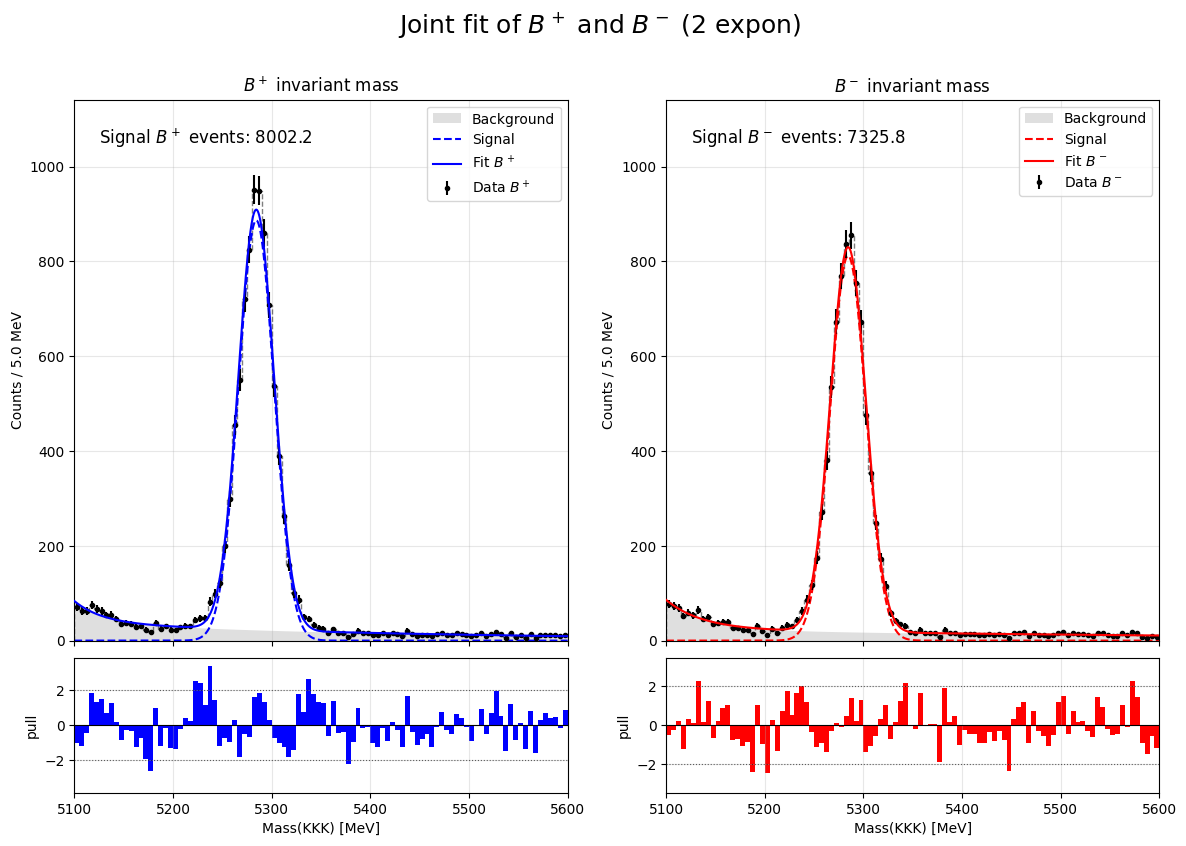

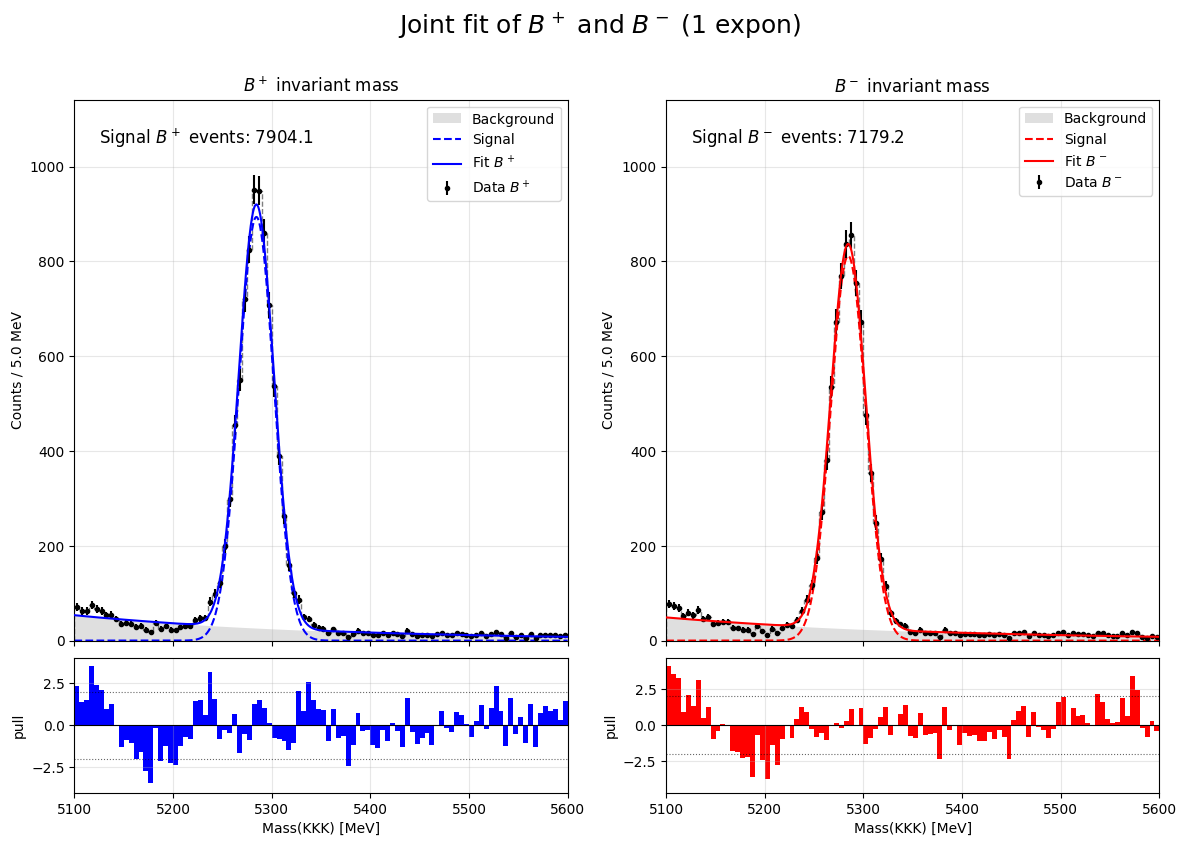

In [98]:
for n, m in joint.items():
    print(f"\n=== {n} exponential(s) ===  valid: {m.valid}")
    lf.print_asymmetry(m)
    print(lf.gof_joint(m, samples, cfg, n_exp=n, bins=50))
    lf.plot_joint_fit(m, samples, cfg, n_exp=n)

In [90]:
Ns = joint[2].values["N_sig"], joint[2].errors["N_sig"]
Nb = joint[2].values["N_bkg_pos"] + joint[2].values["N_bkg_neg"]
Nb_err = np.sqrt(joint[2].covariance["N_bkg_pos","N_bkg_pos"] + joint[2].covariance["N_bkg_neg","N_bkg_neg"]
                 + 2*joint[2].covariance["N_bkg_pos","N_bkg_neg"])

print('Ns: ', Ns[0], "±", Ns[1])
print('Nb (pos): ', joint[2].values["N_bkg_pos"], joint[2].errors["N_bkg_pos"])
print('Nb (neg): ', joint[2].values["N_bkg_neg"], joint[2].errors["N_bkg_neg"])
print('Nb: ', Nb, "±", Nb_err)
n_pos, n_neg = joint[2].values["N_bkg_pos"], joint[2].values["N_bkg_neg"]
n = n_pos + n_neg
a = (n_neg - n_pos) / n
print(f"asymm: {a:.3f} ± {np.sqrt((1 - a**2) / n):.3f}")

Ns:  15327.953800327161 ± 132.96598438037836
Nb (pos):  2290.0107403333354 57.60266431789864
Nb (neg):  2113.099519774695 55.65993609968973
Nb:  4403.110260108031 ± 82.1940162234028
asymm: -0.040 ± 0.015


In [114]:
print("A_CP: ", joint[2].values["A_CP"])
print(f'68% CL: [{joint[2].values["A_CP"]+joint[2].merrors["A_CP"].lower}, {joint[2].values["A_CP"]+joint[2].merrors["A_CP"].upper}]')
joint[2].minos("A_CP", cl=0.95)
print(f'95% CL: [{joint[2].values["A_CP"]+joint[2].merrors["A_CP"].lower}, {joint[2].values["A_CP"]+joint[2].merrors["A_CP"].upper}]')

A_CP:  -0.04412921444784368
68% CL: [-0.05258667519688764, -0.03561271029322588]
95% CL: [-0.06073745056651783, -0.027472100483883703]


### Profiled Likelihood and hypothesis test

In [28]:
best = joint[2]
POIS = ["A_CP", "mu"]                                        # parameters of interest
nuisance = [p for p in best.parameters if p not in POIS]     # everything else is profiled

t, p, _ = lf.wilks_test(best, {"A_CP": 0.0})                 # H0: no CP violation
print(f"H0: A_CP = 0  ->  t = {t:.2f},  p-value = {p:.2e}  ({scipy.stats.norm.ppf(1 - p):.2f} sigma)")

H0: A_CP = 0  ->  t = 26.99,  p-value = 2.05e-07  (5.06 sigma)


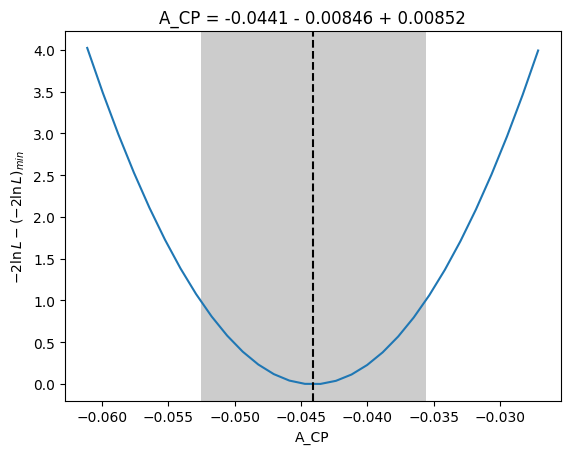

In [29]:
best.draw_mnprofile("A_CP")
plt.ylabel(r"$-2\ln L - (-2\ln L)_{min}$");

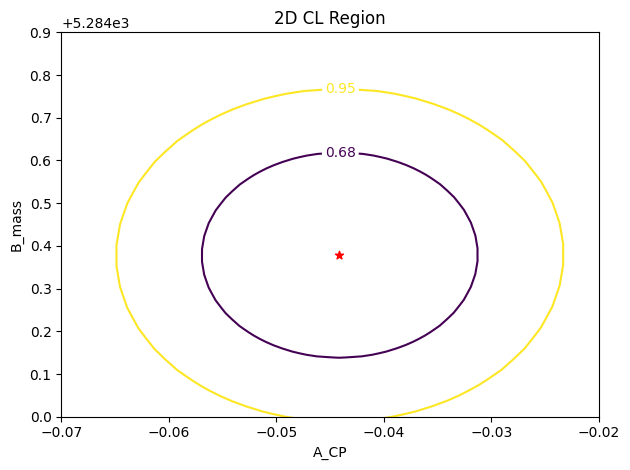

In [30]:
best.draw_mncontour("A_CP", "mu", cl=[0.68, 0.95])
plt.scatter([best.values["A_CP"]], [best.values["mu"]], marker="*", color="r")
plt.title("2D CL Region")
plt.xlabel("A_CP")
plt.ylabel("B_mass")
plt.xlim(-0.07, -0.020)
plt.ylim(5284.0, 5284.9)
plt.tight_layout()

### Coverage check (bootstrap) of Wilks' theorem

  0%|          | 0/1000 [00:00<?, ?it/s]

coverage of the 2.30 (68.3%) threshold: 67.2%   (1000 toys, 0 failed)


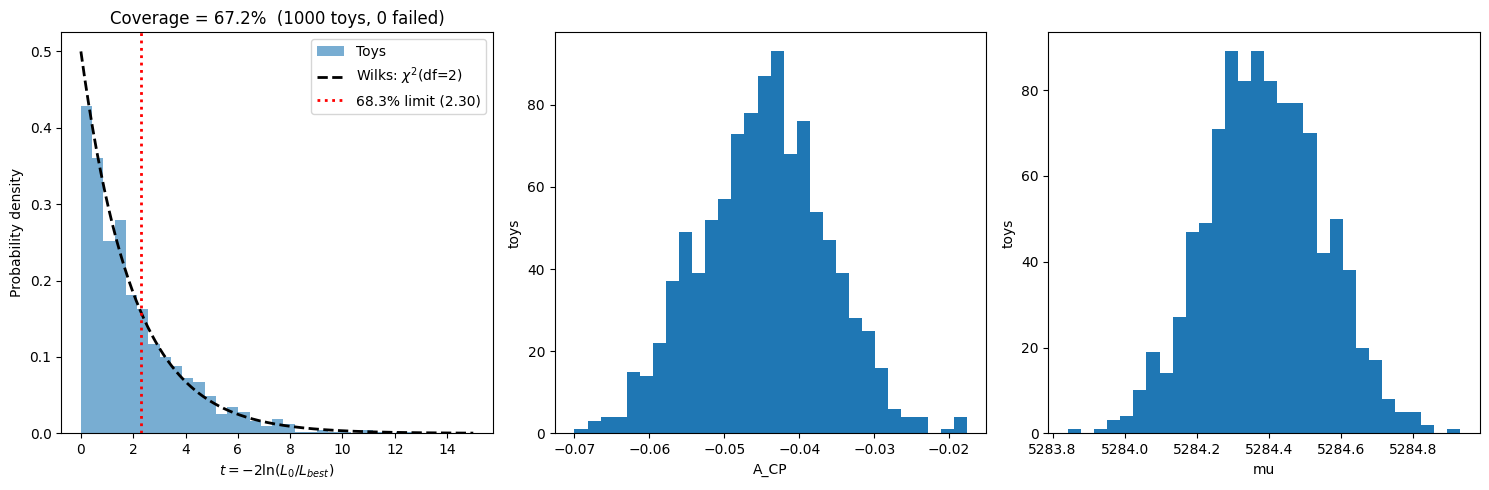

In [ ]:
res = lf.run_coverage_study(data_window, cfg, best, pois=POIS, n_toys=1000, seed=1)
print(f"coverage of the {res.t_crit:.2f} (68.3%) threshold: {res.coverage:.1%}   ({len(res.t_values)} toys, {res.n_failed} failed)")
lf.plot_coverage(res);

### Systematic Uncertanties

1. Change the fit_window limits

In [31]:
# fit_window_limits = {
#     'left':  [5000, 5025, 5050, 5075, 5100, 5125, 5150, 5175, 5200],
#     'right': [5350, 5375, 5400, 5425, 5450, 5475, 5500, 5525, 5550, 5575, 5600, 5625, 5650, 5675, 5700, 5725, 5750, 5775, 5800, 5825, 5850, 5875, 5900, 5925, 5950, 5975, 6000, 6025, 6050, 6075, 6100]
# }

fit_window_limits = {
    'left':  [5000, 5050, 5100, 5150, 5200],
    'right': [5350, 5400, 5450, 5500, 5550, 5600, 5650, 5700, 5750, 5800, 5850, 5900, 5950, 6000, 6050, 6100]
}

In [32]:
res_win = lf.scan_fit_window(data, cfg, fit_window_limits["left"], fit_window_limits["right"])
ok_win = res_win[res_win.valid & res_win.accurate]

scan:   0%|          | 0/80 [00:00<?, ?it/s]

nominal A_CP = -0.04413 ± 0.00850 (stat)
mean A_CP    = -0.04512 ± 0.00175 (syst)
std over windows        = 0.00177
mean err over windows   = 0.00852
max |A_CP - nominal|    = 0.00482


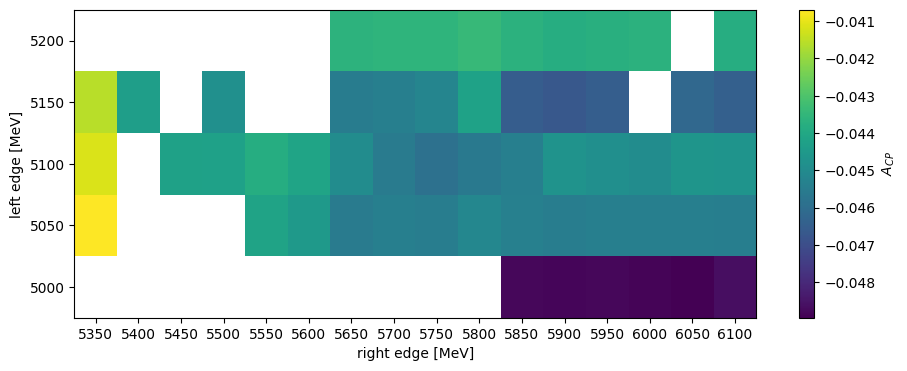

In [33]:
nominal_win = ok_win[(ok_win.left == cfg.fit_window[0]) & (ok_win.right == cfg.fit_window[1])].iloc[0]

pivot_win = ok_win.pivot(index="left", columns="right", values="A_CP")
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.pcolormesh(pivot_win.columns, pivot_win.index, pivot_win.values, shading="nearest")
fig.colorbar(im, label=r"$A_{CP}$")
ax.set(xlabel="right edge [MeV]", ylabel="left edge [MeV]")
ax.set_xticks(pivot_win.columns)
ax.set_yticks(pivot_win.index)

print(f"nominal A_CP = {nominal_win.A_CP:.5f} ± {nominal_win.A_CP_err:.5f} (stat)")
print(f"mean A_CP    = {np.mean(ok_win['A_CP']):.5f} ± {np.std(ok_win['A_CP']):.5f} (syst)")
print(f"std over windows        = {ok_win.A_CP.std():.5f}")
print(f"mean err over windows   = {np.mean(ok_win.A_CP_err):.5f}")
print(f"max |A_CP - nominal|    = {(ok_win.A_CP - nominal_win.A_CP).abs().max():.5f}")

In [115]:
dA = ok_win.A_CP - nominal_win.A_CP
sB = np.sqrt(np.abs(ok_win.A_CP_err**2 - nominal_win.A_CP_err**2))
print(len(ok_win), "of", len(res_win), "windows retained")
print(f"A_CP from {ok_win.A_CP.min():.4f} to {ok_win.A_CP.max():.4f}, RMS of shifts {np.sqrt((dA**2).mean()):.4f}")
print((dA.abs() > 2*sB).sum(), "windows beyond 2 sigma_B")

55 of 80 windows retained
A_CP from -0.0490 to -0.0407, RMS of shifts 0.0020
10 windows beyond 2 sigma_B


2. Change the sig_region limits

In [34]:
sig_region_limits = {
    'left':  [5150, 5170, 5185, 5200, 5215, 5230, 5250],
    'right': [5320, 5335, 5350, 5365, 5380, 5400, 5420]
}

In [35]:
res_sr  = lf.scan_signal_region(data, cfg, sig_region_limits['left'], sig_region_limits['right'])
ok_sr = res_sr[res_sr.valid & res_sr.accurate]

scan:   0%|          | 0/49 [00:00<?, ?it/s]

nominal A_CP = -0.04413 ± 0.00850 (stat)
mean A_CP    = -0.04411 ± 0.00002 (syst)
std over windows        = 0.0000169
mean err over windows   = 0.00850
max |A_CP - nominal|    = 0.00006


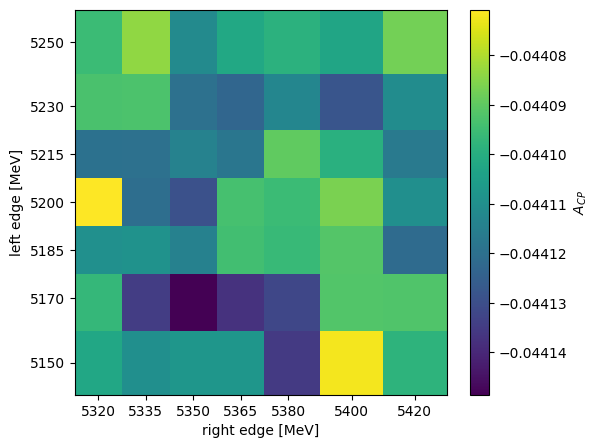

In [119]:
nominal_sr = ok_sr[(ok_sr.sig_lo == cfg.sig_region[0]) & (ok_sr.sig_hi == cfg.sig_region[1])].iloc[0]

pivot_sr = ok_sr.pivot(index="sig_lo", columns="sig_hi", values="A_CP")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(pivot_sr.columns, pivot_sr.index, pivot_sr.values, shading="nearest")
fig.colorbar(im, label=r"$A_{CP}$")
ax.set(xlabel="right edge [MeV]", ylabel="left edge [MeV]")
ax.set_xticks(pivot_sr.columns)
ax.set_yticks(pivot_sr.index)

print(f"nominal A_CP = {nominal_sr.A_CP:.5f} ± {nominal_sr.A_CP_err:.5f} (stat)")
print(f"mean A_CP    = {np.mean(ok_sr['A_CP']):.5f} ± {np.std(ok_sr['A_CP']):.5f} (syst)")
print(f"std over windows        = {ok_sr.A_CP.std():.7f}")
print(f"mean err over windows   = {np.mean(ok_sr.A_CP_err):.5f}")
print(f"max |A_CP - nominal|    = {(ok_sr.A_CP - nominal_sr.A_CP).abs().max():.5f}")

In [118]:
dA = ok_sr.A_CP - nominal_sr.A_CP
sB = np.sqrt(np.abs(ok_sr.A_CP_err**2 - nominal_sr.A_CP_err**2))
print(len(ok_sr), "of", len(res_sr), "windows retained")
print(f"A_CP from {ok_sr.A_CP.min():.7f} to {ok_sr.A_CP.max():.7f}, RMS of shifts {np.sqrt((dA**2).mean()):.7f}")
print((dA.abs() > 2*sB).sum(), "windows beyond 2 sigma_B")

49 of 49 windows retained
A_CP from -0.0441486 to -0.0440708, RMS of shifts 0.0000277
2 windows beyond 2 sigma_B


3. Selection

In [37]:
scan_cuts = {
    "prob_k_min":   [0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8],
    "prob_pi_max":  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6],
}

scan_cuts = {
    "prob_k_min":   np.arange(0.45, 0.81, 0.025),
    "prob_pi_max":  np.arange(0.30, 0.56, 0.025),
}

In [38]:
res_cuts  = lf.scan_preselection_cuts(data, cfg, scan_cuts['prob_k_min'], scan_cuts['prob_pi_max'])
ok_cuts = res_cuts[res_cuts.valid & res_cuts.accurate]

scan:   0%|          | 0/165 [00:00<?, ?it/s]

nominal A_CP = -0.04413        ±   0.00850 (stat)
mean A_CP    = -0.04352 ± 0.00444 (syst)
std over windows        = 0.00445
mean err over windows   = 0.01128
max |A_CP - nominal|    = 0.01119


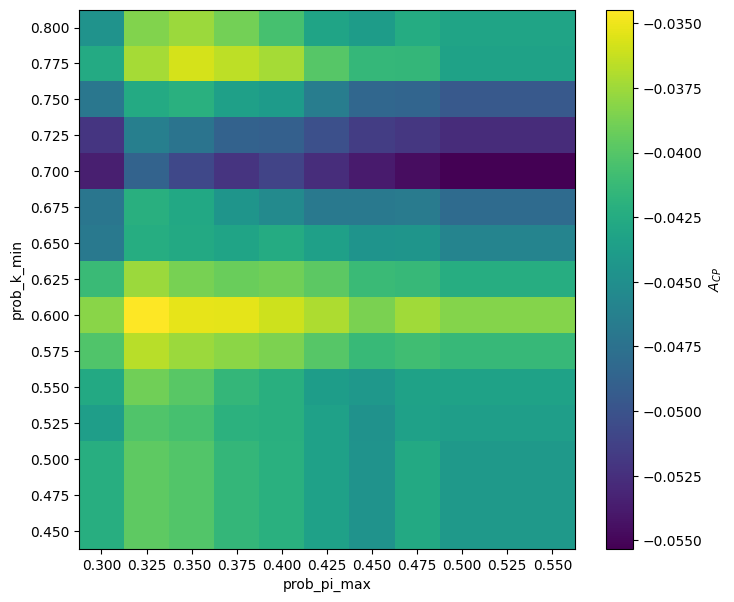

In [39]:
nominal_cuts = ok_cuts[(abs(ok_cuts.prob_k_min-cfg.prob_k_min) < 0.01) & (abs(ok_cuts.prob_pi_max-cfg.prob_pi_max) < 0.01)].iloc[0]

pivot_cuts = ok_cuts.pivot(index="prob_k_min", columns="prob_pi_max", values="A_CP")
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.pcolormesh(pivot_cuts.columns, pivot_cuts.index, pivot_cuts.values, shading="nearest")
fig.colorbar(im, label=r"$A_{CP}$")
ax.set(xlabel="prob_pi_max", ylabel="prob_k_min")
ax.set_xticks(pivot_cuts.columns)
ax.set_yticks(pivot_cuts.index)

print(f"nominal A_CP = {nominal_cuts.A_CP:.5f}        ±   {nominal_cuts.A_CP_err:.5f} (stat)")
print(f"mean A_CP    = {np.mean(ok_cuts['A_CP']):.5f} ± {np.std(ok_cuts['A_CP']):.5f} (syst)")
print(f"std over windows        = {ok_cuts.A_CP.std():.5f}")
print(f"mean err over windows   = {np.mean(ok_cuts.A_CP_err):.5f}")
print(f"max |A_CP - nominal|    = {(ok_cuts.A_CP - nominal_cuts.A_CP).abs().max():.5f}")

In [120]:
dA = ok_cuts.A_CP - nominal_cuts.A_CP
sB = np.sqrt(np.abs(ok_cuts.A_CP_err**2 - nominal_cuts.A_CP_err**2))
print(len(ok_cuts), "of", len(res_cuts), "windows retained")
print(f"A_CP from {ok_cuts.A_CP.min():.7f} to {ok_cuts.A_CP.max():.7f}, RMS of shifts {np.sqrt((dA**2).mean()):.7f}")
print((dA.abs() > 2*sB).sum(), "windows beyond 2 sigma_B")

165 of 165 windows retained
A_CP from -0.0553186 to -0.0344699, RMS of shifts 0.0044781
0 windows beyond 2 sigma_B


# Dalitz plots

### Simulation Data

In [40]:
# For Simulation Data the charges are mixed
df_sim[['H1_Charge', 'H2_Charge', 'H3_Charge', 'B_Charge']][:5]

,H1_Charge,H2_Charge,H3_Charge,B_Charge
0,-1,1,-1,-1
1,1,-1,-1,-1
2,-1,1,1,1
3,1,-1,1,1
4,-1,1,-1,-1


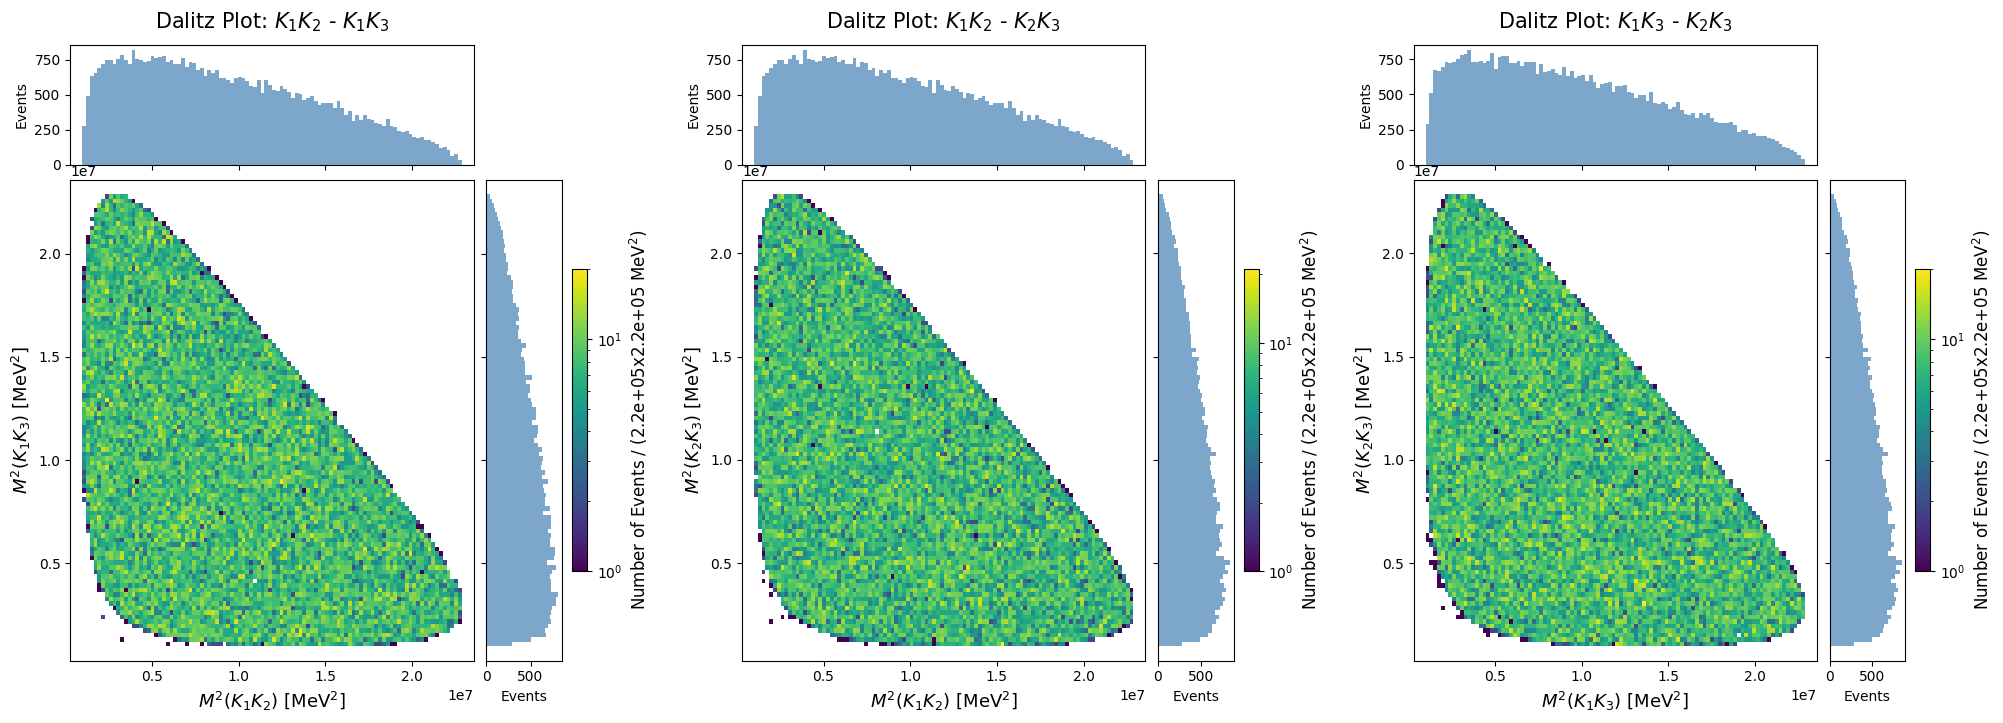

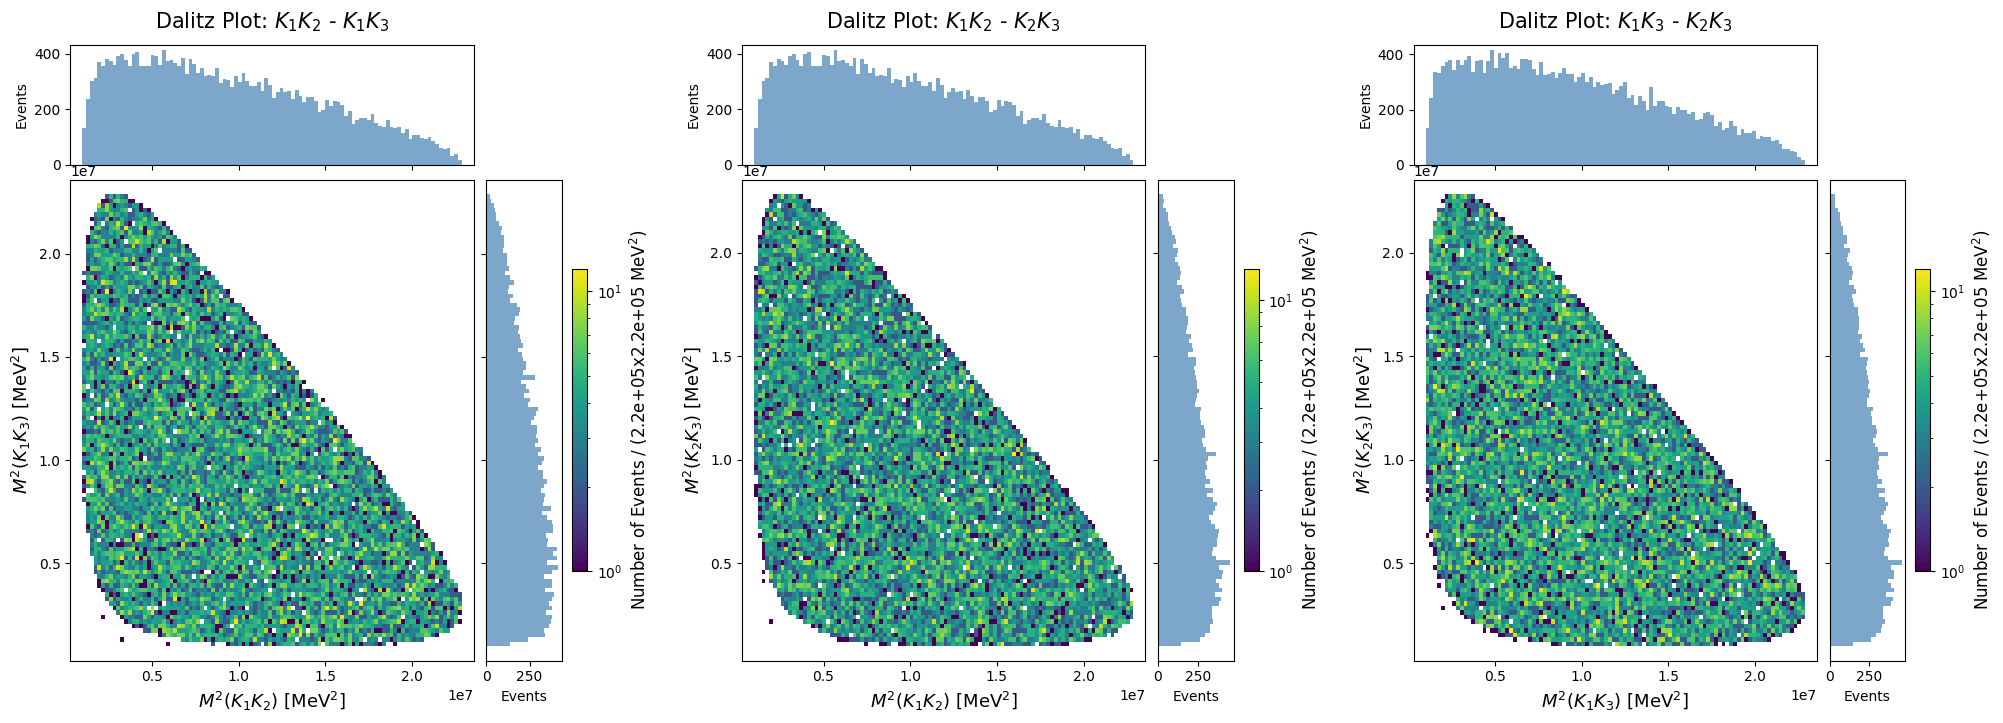

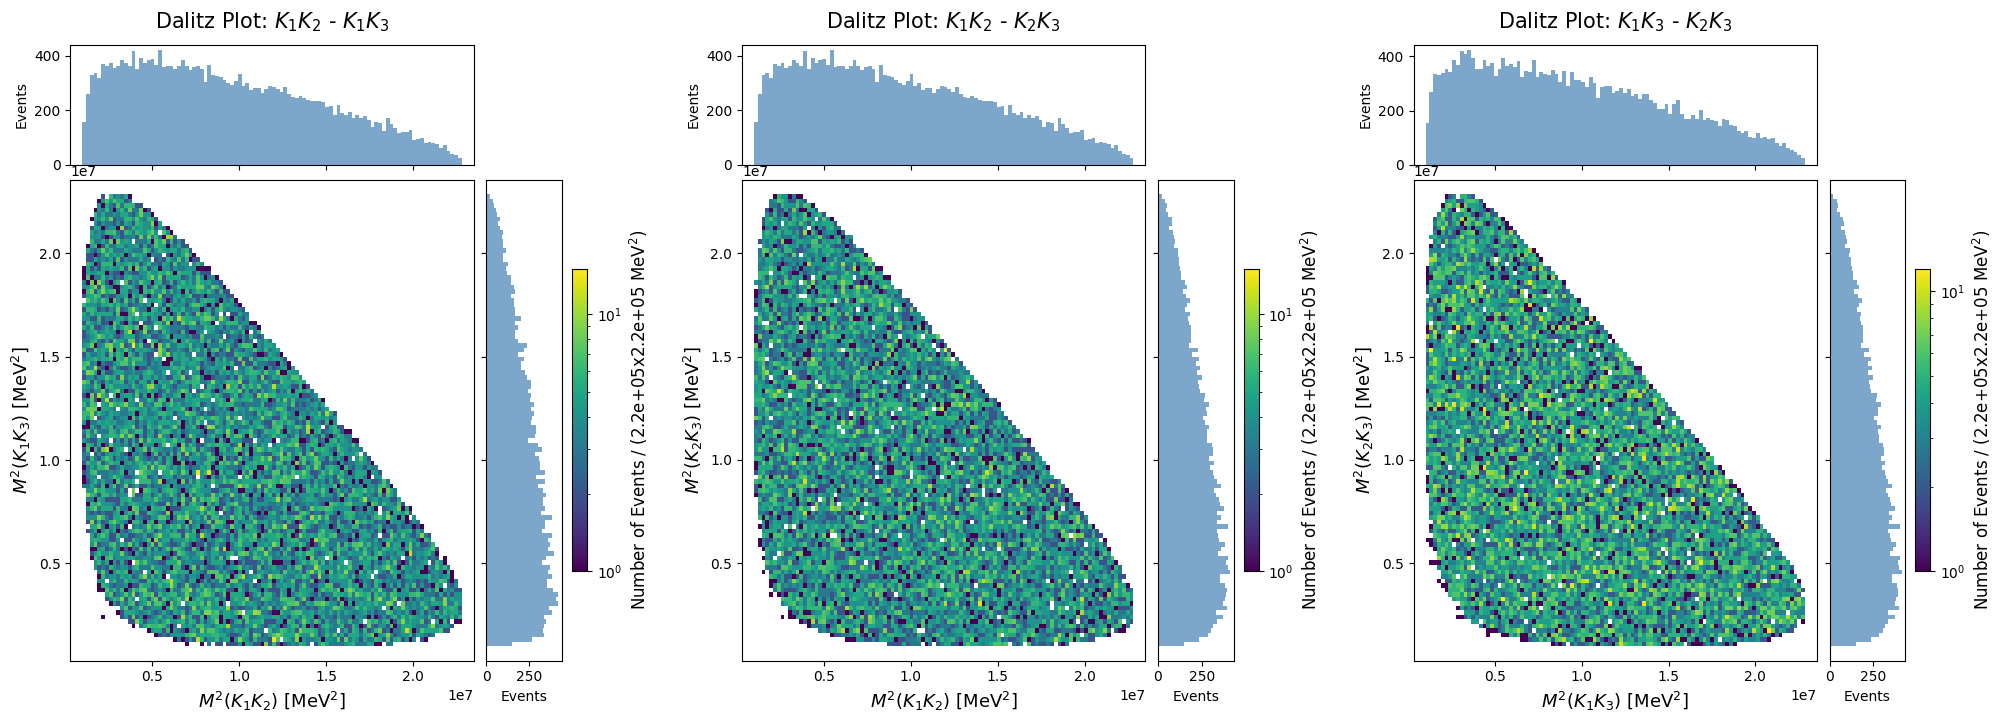

In [41]:
df_sim_charge_split = lf.split_by_charge(df_sim, col=df_sim.columns)
fig = lf.dalitz_plot(cfg, data=df_sim,                     bins=100)
fig = lf.dalitz_plot(cfg, data=df_sim_charge_split['pos'], bins=100)
fig = lf.dalitz_plot(cfg, data=df_sim_charge_split['neg'], bins=100)

### Real Data

#### Basic Dalitz Plot

In [42]:
# For Real Data the charge of 2 and 3 is the same (also equal to B charge)
#    --> 12 = 0
#    --> 13 = 0
#    --> 23 = ++/-- (should be no peak of M_23 in the Dalitz Plot) --> OK!

data[['H1_Charge', 'H2_Charge', 'H3_Charge', 'B_Charge']][:5]

,H1_Charge,H2_Charge,H3_Charge,B_Charge
0,-1,1,1,1
1,1,-1,-1,-1
2,-1,1,1,1
3,-1,1,1,1
4,1,-1,-1,-1


In [43]:
# # apply a cut on the B mass values (signal) to reduce the bkg
# data_signal = lf.select_window(data, cfg.sig_region)
# data_signal = data
# # plt.hist(data_signal['B_Mass'], bins=100);

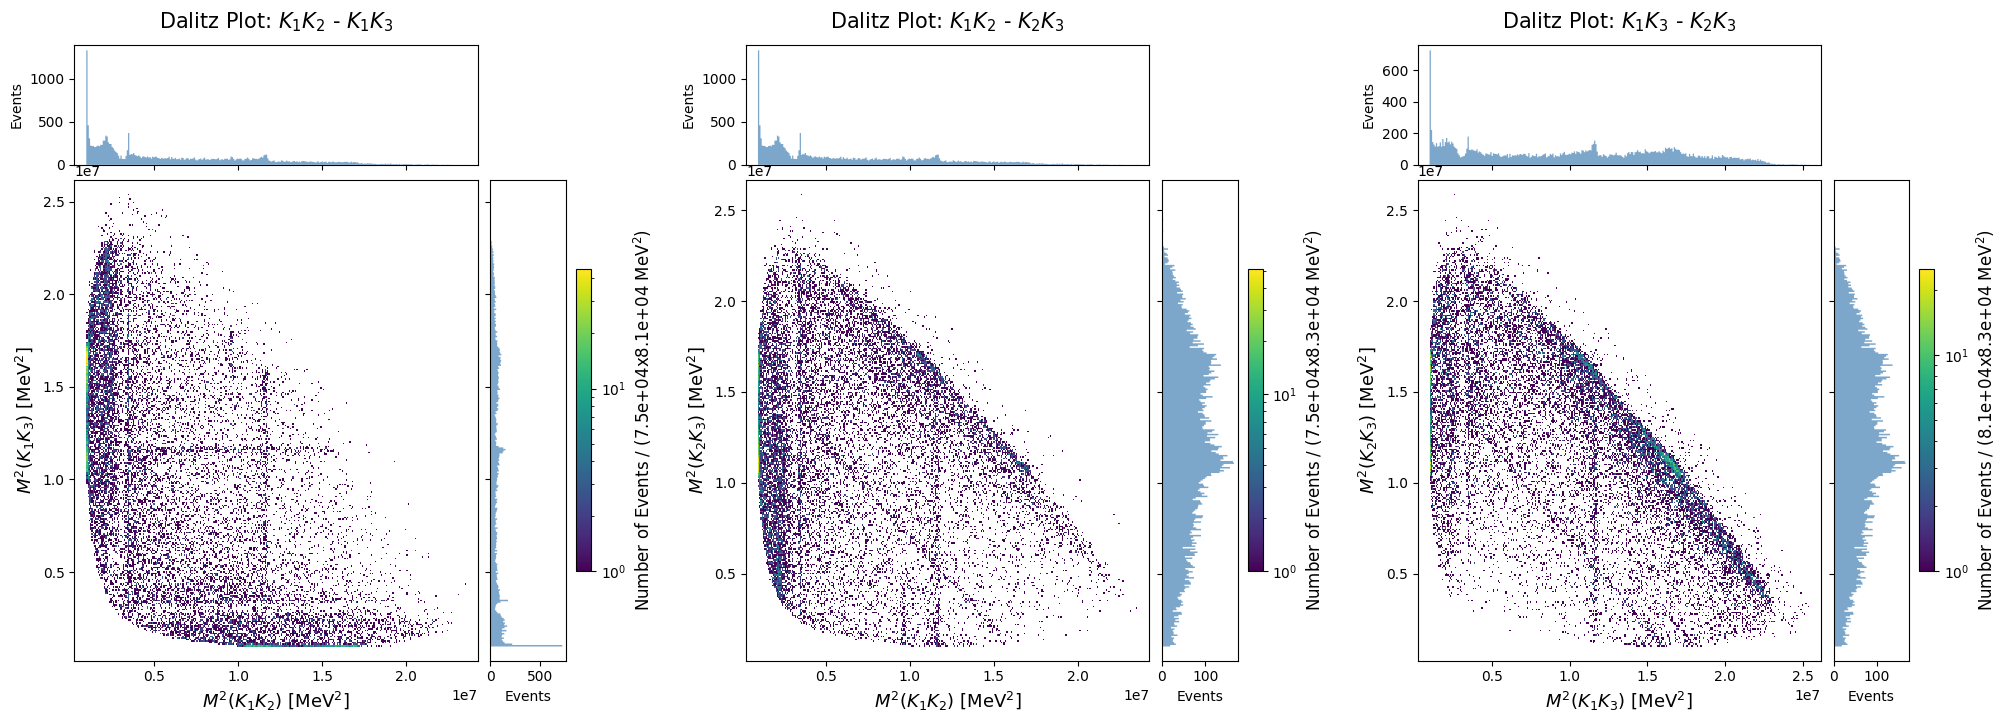

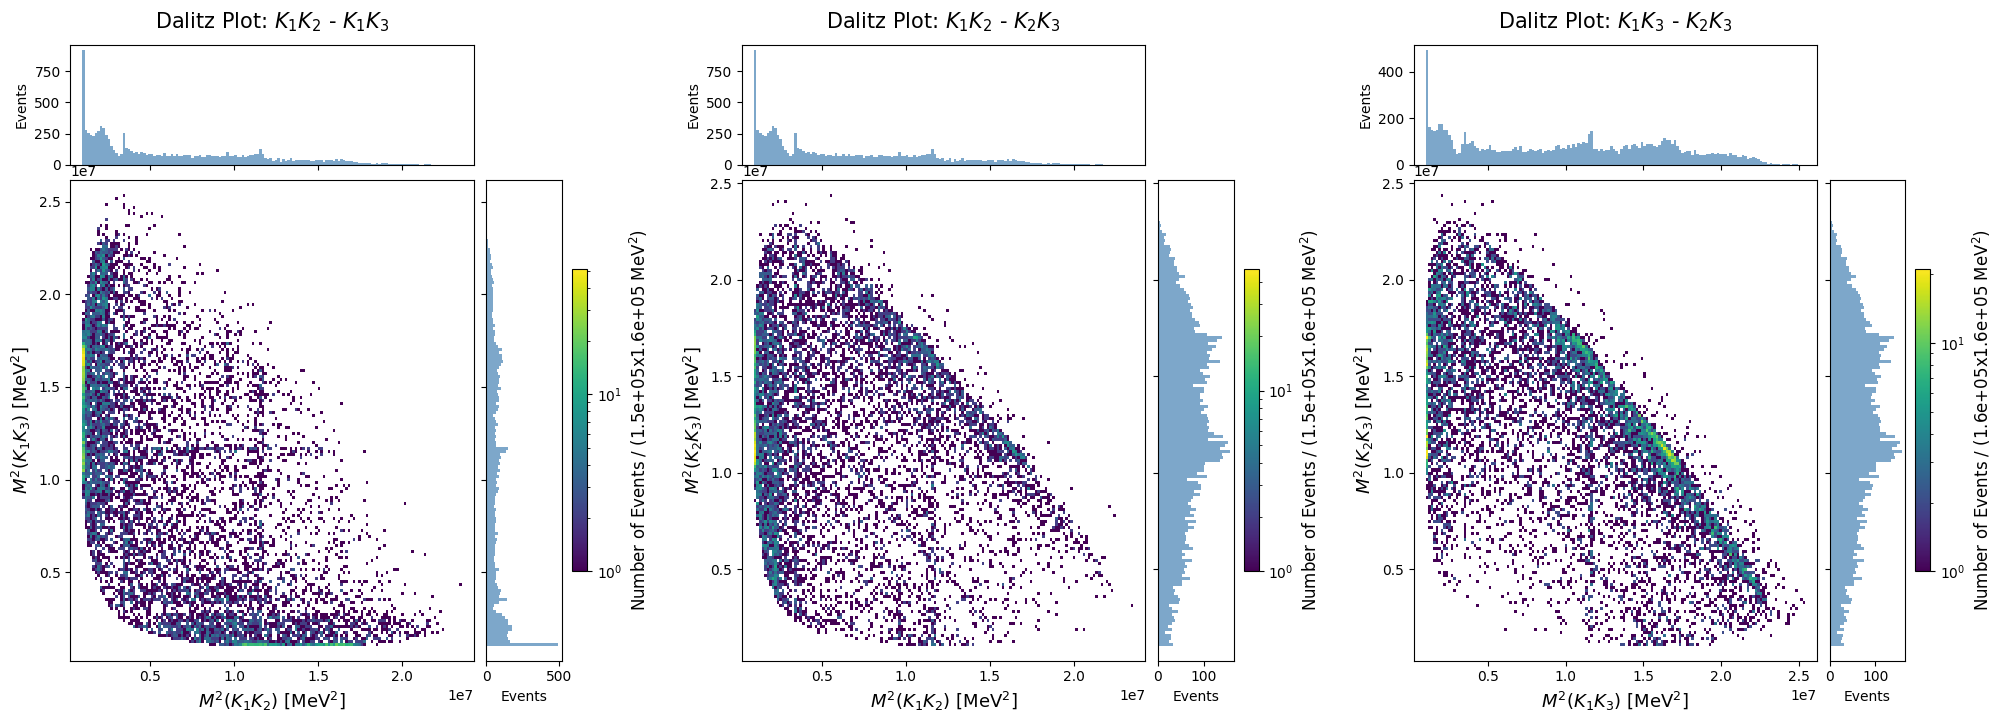

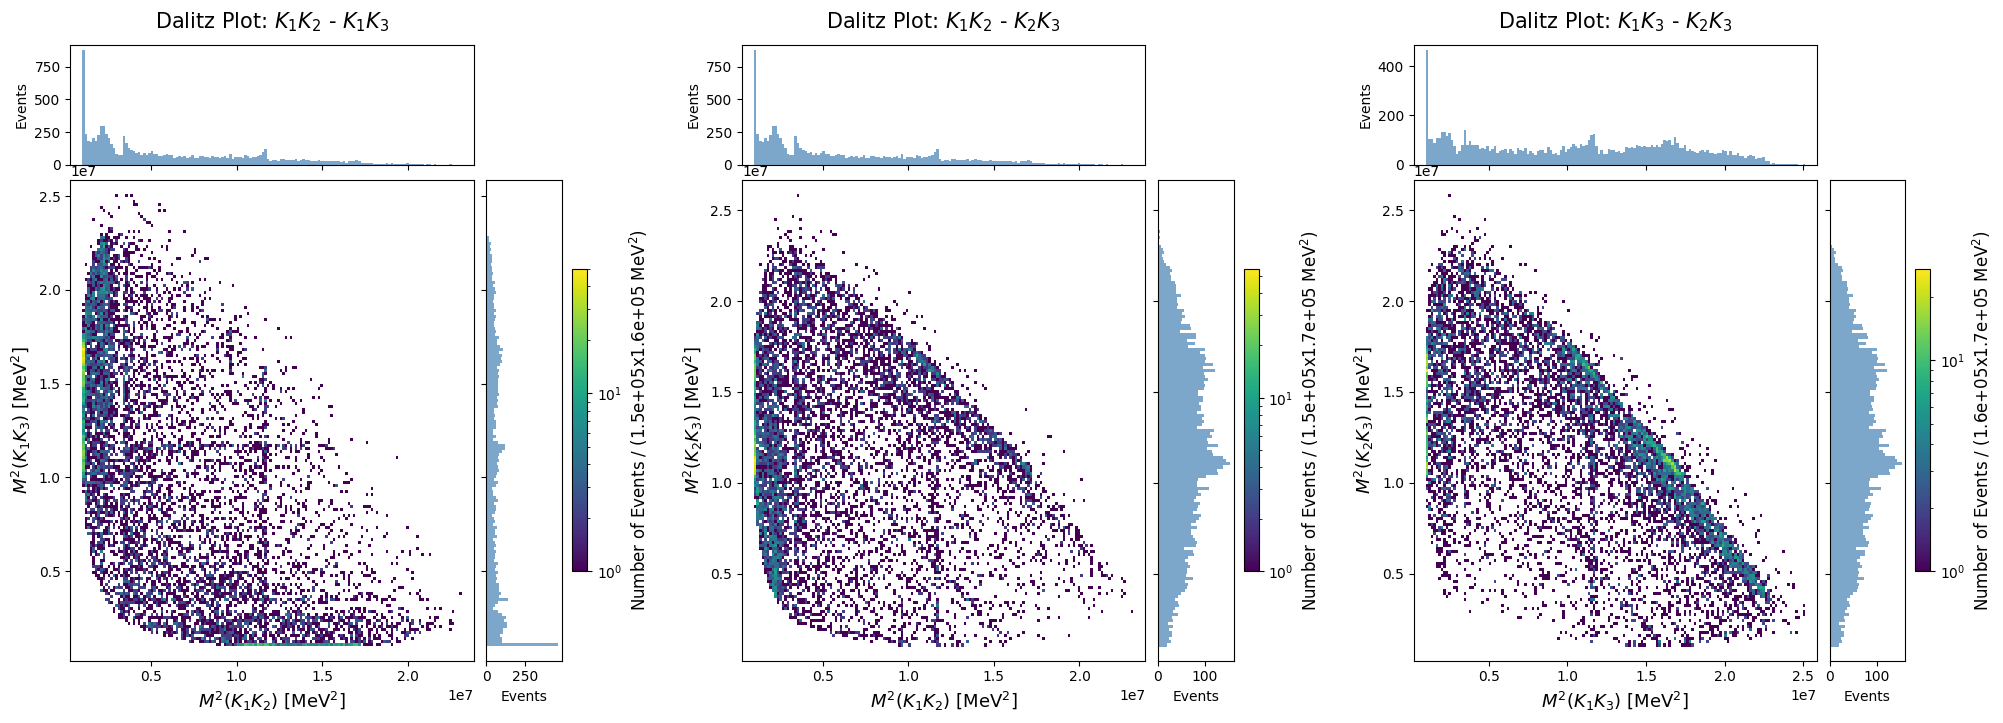

In [44]:
data_charge_split = lf.split_by_charge(data_window, col=data.columns)
fig, *_ = lf.dalitz_plot(cfg, data=data_window,              bins=300)
fig, *_ = lf.dalitz_plot(cfg, data=data_charge_split['pos'], bins=150)
fig, *_ = lf.dalitz_plot(cfg, data=data_charge_split['neg'], bins=150)

B charge:  pos
   Mass:  1865.475810617763 MeV
   Mass:  3398.529093593286 MeV
B charge:  neg
   Mass:  1865.475810617763 MeV
   Mass:  3398.529093593286 MeV


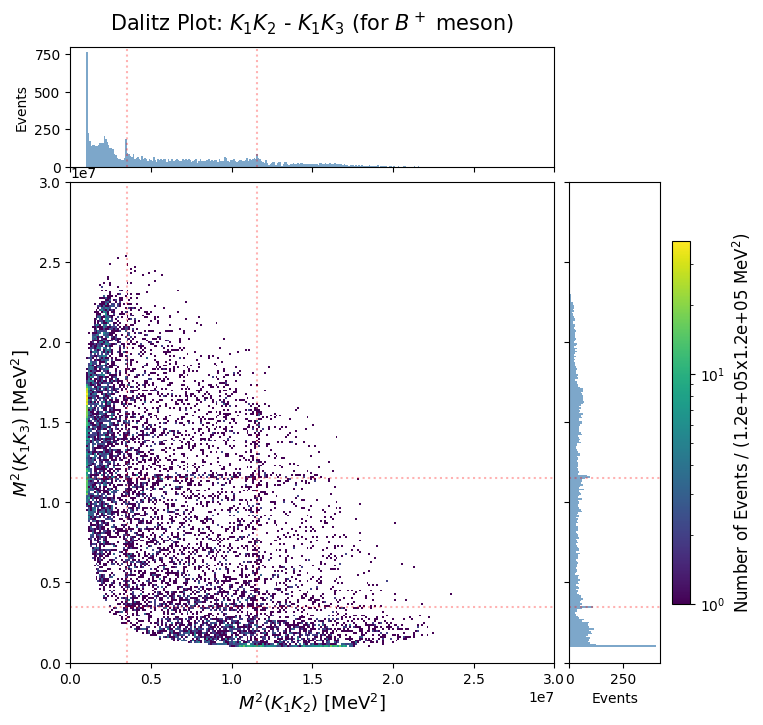

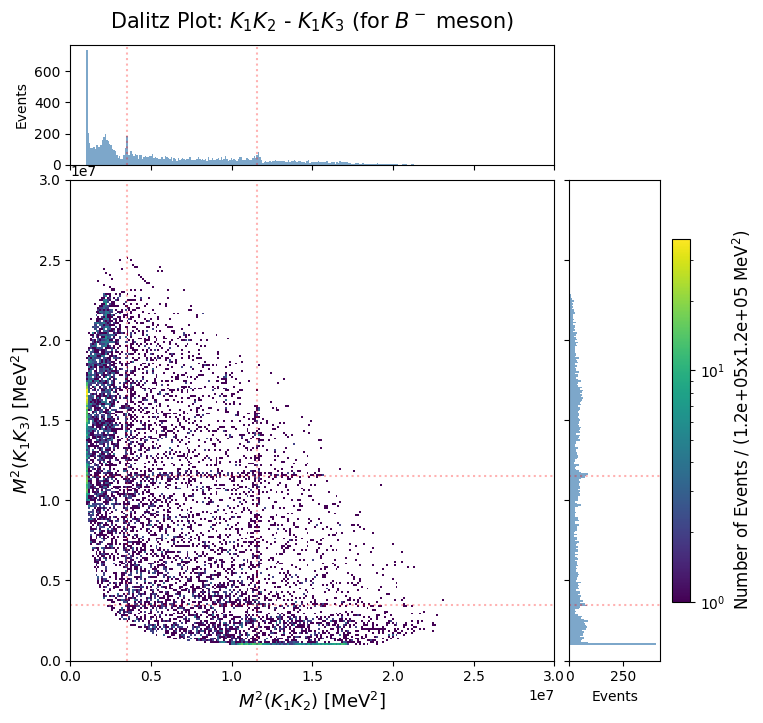

In [45]:
for charge, data_split in data_charge_split.items():
    print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *_ = lf.dalitz_plot(cfg, mass=interesting_mass, bins=250, range=[[0,3e7],[0,3e7]],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')

    possible_peaks = [0.348e7, 1.155e7]
    for possible_peak in possible_peaks:
        ax.axvline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax.axhline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax_top.axvline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        ax_left.axhline(possible_peak, 0,1, color='r', linestyle=':', alpha=0.3);
        print("   Mass: ", np.sqrt(possible_peak), "MeV")

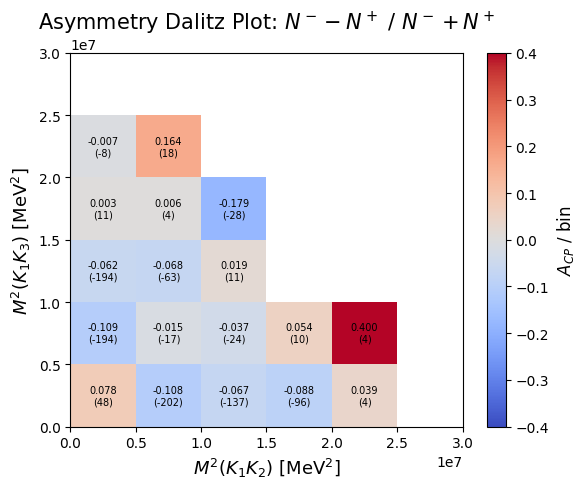

C:\Users\marco\AppData\Local\Temp\ipykernel_1988\4121470509.py:61: RuntimeWarning: invalid value encountered in divide
  histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))
C:\Users\marco\AppData\Local\Temp\ipykernel_1988\4121470509.py:73: RuntimeWarning: invalid value encountered in scalar divide
  val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])


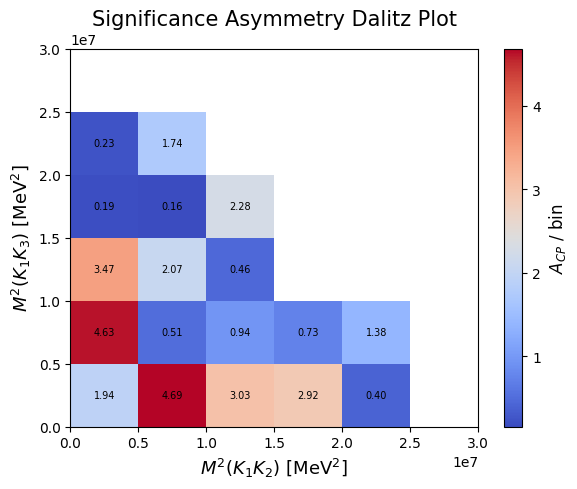

In [46]:
bins_histo_asymm=6

histo = {}
for charge, data_split in data_charge_split.items():
    # print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *histo[charge] = lf.dalitz_plot(cfg, mass=interesting_mass, bins=bins_histo_asymm, range=[[0,3e7],[0,3e7]],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')
    plt.close()


x_centers = np.array((histo['neg'][1][:-1] + histo['neg'][1][1:]) / 2)
y_centers = np.array((histo['neg'][2][:-1] + histo['neg'][2][1:]) / 2)

with np.errstate(divide='ignore', invalid='ignore'):
    histo_diff = histo['neg'][0] - histo['pos'][0]
    histo_A_CP, histo_err_A_CP = lf.raw_asymmetry(histo['pos'][0], histo['neg'][0])
    histo_A_CP = np.nan_to_num(histo_A_CP, nan=0.0)
    histo_err_A_CP = np.nan_to_num(histo_err_A_CP, nan=0.0)

histo_A_CP_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, histo_A_CP)
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_A_CP_masked.T,
    cmap='coolwarm', 
    norm=CenteredNorm(vcenter=0)
)
for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = histo_A_CP[i, j]
        err_val2 = histo_err_A_CP[i, j]
        
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.3f}\n({int(val1)})",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Asymmetry Dalitz Plot: $N^- - N^+$ / $N^- + N^+$", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

# -----------------------------------------------------------------------------------------------------------

histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_significance_masked.T, 
    cmap='coolwarm', 
    # norm=CenteredNorm(vcenter=0)
)

for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.2f}",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Significance Asymmetry Dalitz Plot", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

#### Removing Charm Resonances

**Dalitz Plot**

B charge:  pos
B charge:  neg


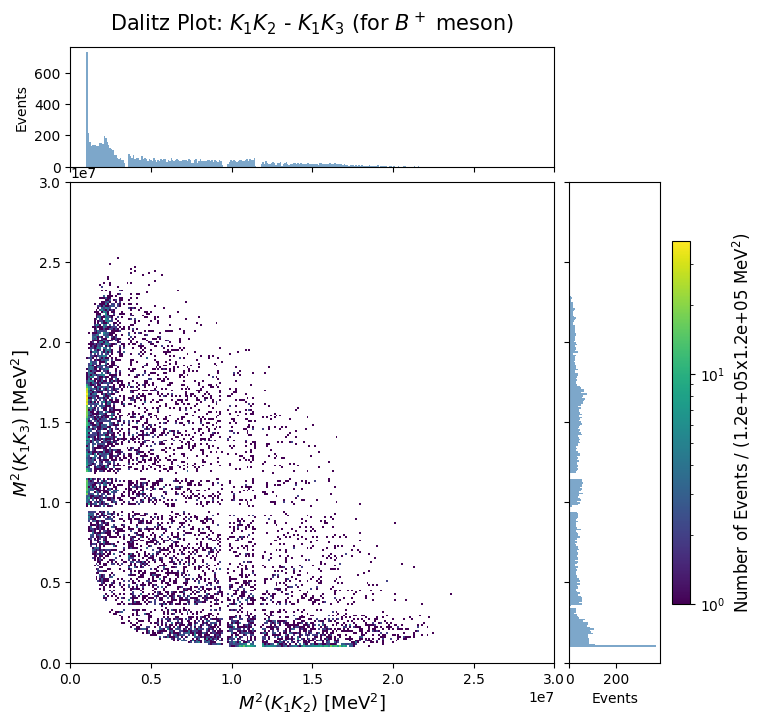

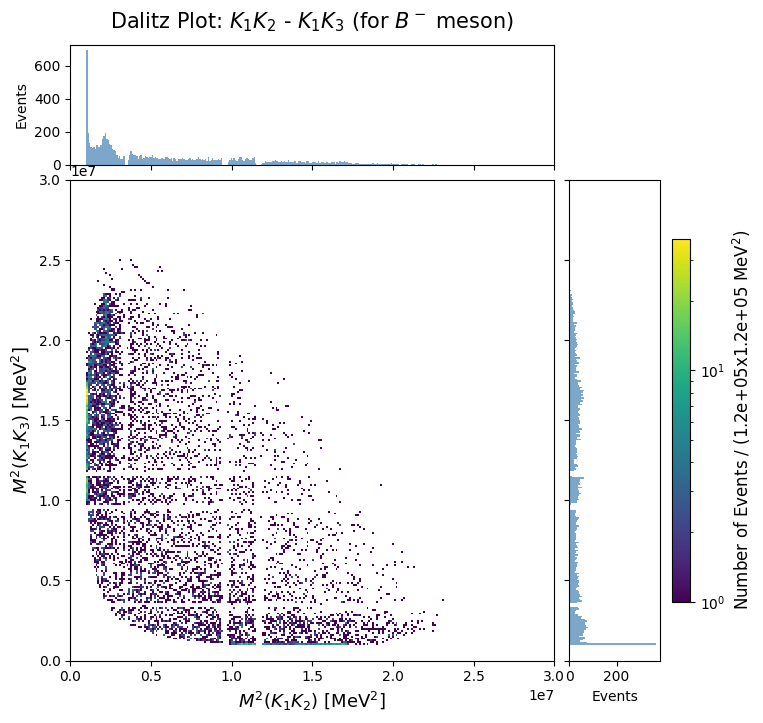

In [47]:
data_charge_split = lf.split_by_charge(data_window, col=data.columns)
for charge, data_split in data_charge_split.items():
    print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *_ = lf.dalitz_plot(cfg, mass=interesting_mass, bins=250, range=[[0,3e7],[0,3e7]], remove_resonances=['D', 'J', 'chi'],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')

**Asymmetry without Resonances**


=== 2 exponential(s) ===  valid: True
A_CP = -0.0480 ± 0.0092   (relative error 19.1%, Hesse significance 5.24 sigma)
Chi2:         416.09
NDOF:         388
Chi2 / NDOF:  1.072
p-value:      0.1565
H0: A_CP = 0  ->  t = 27.52,  p-value = 1.55e-07  (5.12 sigma)


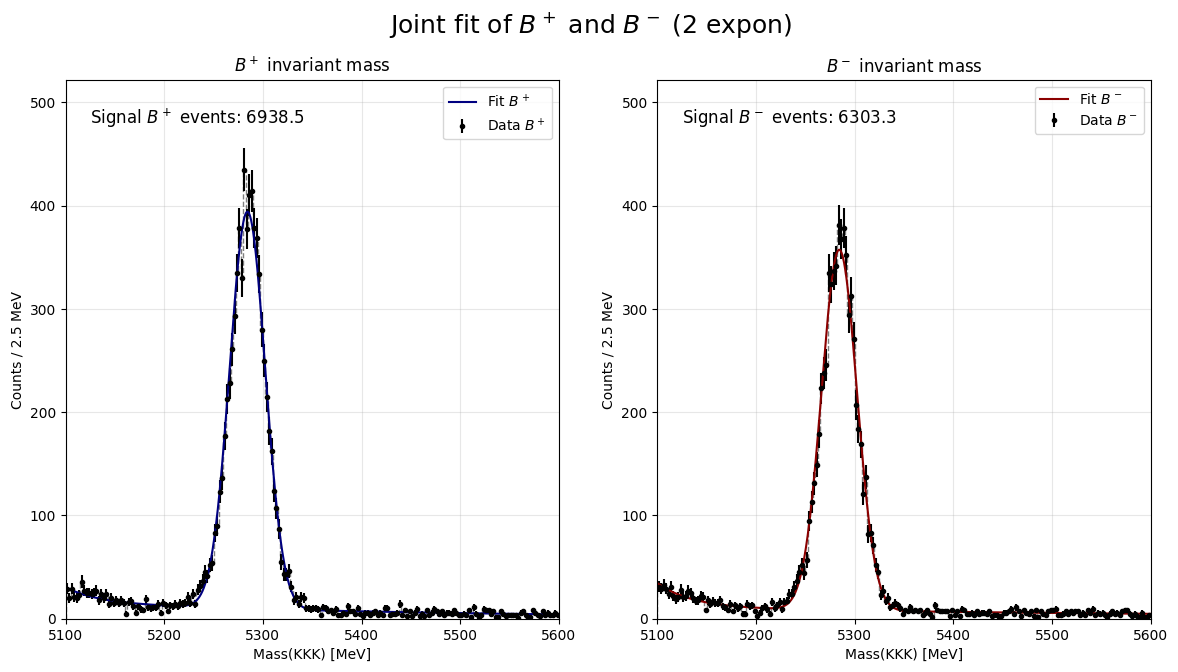

In [ ]:
# remove the resonances and compute the asymmetry (with joint_fit)
data_without_resonances = lf.remove_charm_resonances(cfg, data_window, remove=['D', 'chi'])
samples_without_resonances = lf.split_by_charge(data_without_resonances, col='B_Mass')
joint_without_resonances = {n: lf.fit_joint(samples_without_resonances, cfg, n_exp=n, minos=True) for n in [2]}

for n, m in joint_without_resonances.items():
    print(f"\n=== {n} exponential(s) ===  valid: {m.valid}")
    lf.print_asymmetry(m)
    print(lf.gof_joint(m, samples_without_resonances, cfg, n_exp=n))
    lf.plot_joint_fit(m, samples_without_resonances, cfg, n_exp=n)


best_without_resonances = joint_without_resonances[2]
t, p, _ = lf.wilks_test(best_without_resonances, {"A_CP": 0.0})                 # H0: no CP violation
print(f"H0: A_CP = 0  ->  t = {t:.2f},  p-value = {p:.2e}  ({scipy.stats.norm.ppf(1 - p):.2f} sigma)")

**Asymmetry Dalitz Plot**

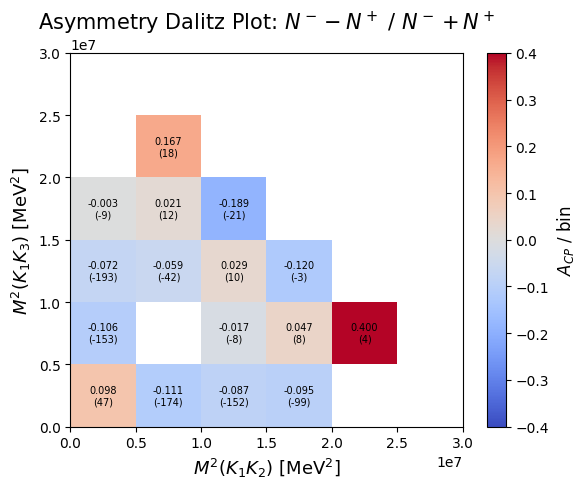

C:\Users\marco\AppData\Local\Temp\ipykernel_1988\3790051756.py:61: RuntimeWarning: divide by zero encountered in divide
  histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))
C:\Users\marco\AppData\Local\Temp\ipykernel_1988\3790051756.py:61: RuntimeWarning: invalid value encountered in divide
  histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))
C:\Users\marco\AppData\Local\Temp\ipykernel_1988\3790051756.py:73: RuntimeWarning: divide by zero encountered in scalar divide
  val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])
C:\Users\marco\AppData\Local\Temp\ipykernel_1988\3790051756.py:73: RuntimeWarning: invalid value encountered in scalar divide
  val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])


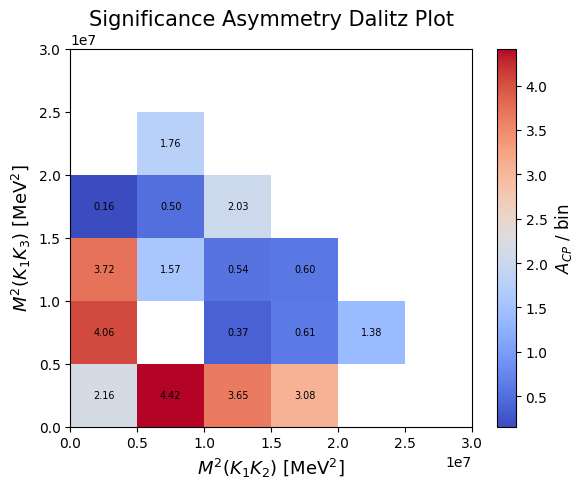

In [49]:
bins_histo_asymm=6

histo = {}
for charge, data_split in data_charge_split.items():
    # print("B charge: ", charge)
    interesting_mass = {}
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    interesting_mass['12'] = all_mass['12']
    interesting_mass['13'] = all_mass['13']

    fig, ax, ax_top, ax_left, *histo[charge] = lf.dalitz_plot(cfg, mass=interesting_mass, bins=bins_histo_asymm, range=[[0,3e7],[0,3e7]], remove_resonances=['D', 'J', 'chi'],
                                                    add_title=r' (for $B^+$ meson)' if charge=='pos' else r' (for $B^-$ meson)')
    plt.close()


x_centers = np.array((histo['neg'][1][:-1] + histo['neg'][1][1:]) / 2)
y_centers = np.array((histo['neg'][2][:-1] + histo['neg'][2][1:]) / 2)

with np.errstate(divide='ignore', invalid='ignore'):
    histo_diff = histo['neg'][0] - histo['pos'][0]
    histo_A_CP, histo_err_A_CP = lf.raw_asymmetry(histo['pos'][0], histo['neg'][0])
    histo_A_CP = np.nan_to_num(histo_A_CP, nan=0.0)
    histo_err_A_CP = np.nan_to_num(histo_err_A_CP, nan=0.0)

histo_A_CP_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, histo_A_CP)
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_A_CP_masked.T,
    cmap='coolwarm', 
    norm=CenteredNorm(vcenter=0)
)
for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = histo_A_CP[i, j]
        err_val2 = histo_err_A_CP[i, j]
        
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.3f}\n({int(val1)})",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Asymmetry Dalitz Plot: $N^- - N^+$ / $N^- + N^+$", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

# -----------------------------------------------------------------------------------------------------------

histo_significance_masked = np.ma.masked_where(np.abs(histo_diff) <= 1, abs(histo_A_CP/histo_err_A_CP))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.pcolormesh(
    histo['pos'][1], histo['pos'][2], histo_significance_masked.T, 
    cmap='coolwarm', 
    # norm=CenteredNorm(vcenter=0)
)

for i in np.arange(len(x_centers)):
    for j in np.arange(len(y_centers)):
        val1 = histo_diff[i, j]
        val2 = abs(histo_A_CP[i, j] / histo_err_A_CP[i, j])
        if abs(val1) > 1:
            ax.text(
                x_centers[i],
                y_centers[j],
                f"{val2:.2f}",
                ha='center',
                va='center',
                fontsize=7,
                color='black'
            )

ax.set_xlabel(r"$M^2(K_1K_2)$ [MeV$^2$]", fontsize=13)
ax.set_ylabel(r"$M^2(K_1K_3)$ [MeV$^2$]", fontsize=13)
ax.set_title(r"Significance Asymmetry Dalitz Plot", fontsize=15)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$A_{CP}$ / bin", fontsize=12)
fig.tight_layout()
plt.show()

#### Selecting Dalitz Plot Regions for A_CP Measurement

In [50]:
cut_dalitz_mass = {}
for charge, data_split in data_charge_split.items():
    all_mass = {f'{i}{j}': lf.invariant_mass(data_split, cfg, particles=(i,j)) for i,j in list(itertools.combinations(cfg.particles, 2))}
    mask_dalitz_plot = (all_mass['12']**2 <= 1.0e7) & (all_mass['12']**2 >= 0.5e7) & (all_mass['13']**2 <= 0.5e7) & (all_mass['13']**2 >= 0.0e7)
    cut_dalitz_mass[charge] = data_split[mask_dalitz_plot]

events in fit window [5100.0, 5600.0] MeV: 1878
  B+ : 1040   B- : 838  -->  raw A_CP = -0.107561 ± 0.022942
  magnet down: 1096   magnet up: 782


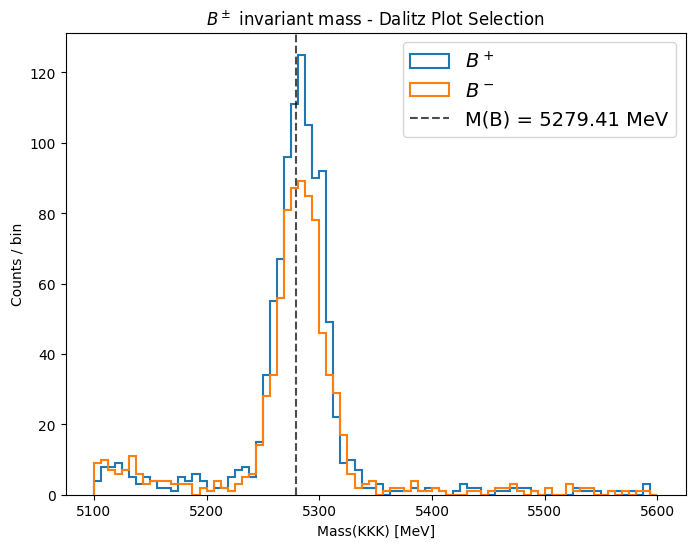

In [51]:
lf.plot_mass_by_charge(pd.concat([cut_dalitz_mass['pos'], cut_dalitz_mass['neg']], ignore_index=True), cfg, bins=80, bin_range=cfg.fit_window,
                       title=r"$B^\pm$ invariant mass - Dalitz Plot Selection")
lf.print_event_summary(pd.concat([cut_dalitz_mass['pos'], cut_dalitz_mass['neg']], ignore_index=True), cfg)

In [52]:
joint_cut_dalitz_mass = {n: lf.fit_joint({'pos': cut_dalitz_mass['pos']['B_Mass'], 'neg': cut_dalitz_mass['neg']['B_Mass']}, cfg, n_exp=n, minos=True) for n in (2, 1)}
display(joint_cut_dalitz_mass[1])

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -3327                      │             Nfcn = 1064              │
│ EDM = 5.65e-05 (Goal: 0.0002)    │            time = 0.4 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name      │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig     │  1.52e3   │  0.04e3   │  -0.04e3   │   0.04e3   │    0    │         │       │
│ 1 │ A_CP      │  -0.133   │   0.026   │   -0.026   │   0.026    │   -1    │    1    │       │
│ 2 │ mu        │ 5.2843e3  │ 0.0005e3  │ -0.0005e3  │  0.0005e3  │  5200   │  5350   │       │
│ 3 │ sigma     │   18.1    │    0.4    │    -0.4    │    0.4     │    1    │   100   │       │
│ 4 │ N_bkg_pos │    180    │    15     │    -15     │     16     │    0    │         │       │
│ 5 │ lam1_pos  │  4.8e-3   │  0.6e-3   │  -0.6e-3   │   0.6e-3   │  1e-06  │    1    │       │
│ 6 │ N_bkg_neg │    180    │    15     │    -15     │     16     │    0    │         │       │
│ 7 │ lam1_neg  │  5.1e-3   │  0.6e-3   │  -0.6e-3   │   0.6e-3   │  1e-06  │    1    │       │
└───┴───────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       N_bkg_neg       │       lam1_neg        │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │    -40    │    40     │  -0.026   │   0.026   │   -0.5    │    0.5    │   -0.4    │    0.4    │    -15    │    16     │  -0.6e-3  │  0.6e-3   │    -15    │    16     │  -0.6e-3  │  0.6e-3   │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘
┌───────────┬──────────────────────────────────────────────────────────────────────────────

In [53]:
best_cut_dalitz_mass = joint_cut_dalitz_mass[2]
POIS = ["A_CP", "mu"]                                        # parameters of interest
nuisance = [p for p in best_cut_dalitz_mass.parameters if p not in POIS]     # everything else is profiled

t, p, _ = lf.wilks_test(best_cut_dalitz_mass, {"A_CP": 0.0})                 # H0: no CP violation
print(f"H0: A_CP = 0  ->  t = {t:.2f},  p-value = {p:.2e}  ({scipy.stats.norm.ppf(1 - p):.2f} sigma)")

H0: A_CP = 0  ->  t = 22.93,  p-value = 1.68e-06  (4.65 sigma)


### Ordering Dalitz variables
You can make a further improvement to allow you to observe the resonances easier. Your resonances R<sup>0</sup><sub>2</sub> and R<sup>0</sup><sub>3</sub> are both composed of the same particle types, K<sup>+</sup>K<sup>-</sup>, and hence have the same distributions. It is useful to impose an ordering which distinguishes the resonances. We can call the resonances R<sup>0</sup><sub>Low</sub> and R<sup>0</sup><sub>High</sub>. In each event R<sup>0</sup><sub>Low</sub> is the resonance with the lower mass and the other corresponds to the higher mass combination of kaons. You can now use the mass of these ordered resonances as your Dalitz plot variables, thus effectively "folding" your Dalitz plot so that one axis always has a higher value than the other.


In [54]:
# make a new Dalitz plot with a mass ordering of the axes

### Hint

**Ordered Dalitz plot** - You can find the maximum of the mass of R<sup>0</sup><sub>Low</sub> vs R<sup>0</sup><sub>High</sub> elementwise on one axis, and the minimum of on the other. You can use `numpy.min(a,b)` and `numpy.max(a,b)` to perform elementwise comparisons between two arrays `a` and `b` and return one array filled by either the individual min/max element from the elementwise comparisons.

# Further analyses

## Adding extra sophistication

### Systematic Uncertainties
In this analysis you considered the statistical uncertainty on the result. This occurs as a result of having only a limited number of events. In addition there are [systematic uncertainties](https://en.wikipedia.org/wiki/Observational_error#Systematic_versus_random_error), these arise from biases in your measurement. Here we discuss three sources of these for this analysis.
<ul>
<li> Production asymmetry. The LHC is a proton-proton collider and hence the initial state of the collision is not matter antimatter symmetric. Consequently B<sup>+</sup> and B<sup>-</sup> mesons may not be produced at exactly the same rates. This small production asymmetry it is estimated could be approximately 1%. It can also be measured from the data, as discussed in the LHCb paper.</li>
<li> Detection asymmetry. The LHCb detector could be more efficient for detecting either the B<sup>+</sup> or the B<sup>-</sup> final states. This is because the positive and negative kaons will be bent by the magnet indifferent directions in the detector. If the efficiency of the detector is higher in one region than another this will lead to higher efficiencies for K<sup>+</sup> or K<sup>-</sup> and hence for B<sup>+</sup> or B<sup>-</sup>. For this reason the magnetic field of the LHCb detector is regularly reversed. You used data in this analysis in which the magnetic field was both up and down and hence the effect will (partially) cancel. By comparing results for the two magnet polarities separately you can check the size of this effect. When loading the data above both polarities were combined, you can instead load them independently to measure the difference between the two datasets.</li>
<li> Analysis technique. The analysis technique you have used may bias the result. A major simplification we made in the analysis above was to neglect 'background' events. We imposed a selection to select a sample of predominantly signal events but have not accounted for the effect of the residual background events.</li>
</ul>

## Further analyses

The LHCb papers using this data set that you are using analysed four decay channels of the charged B mesons. You can perform any of these analyses.
<ul>
<li>B<sup>+</sup> → K<sup>+</sup>K<sup>+</sup>K<sup>−</sup> (and anti-particle equivalent). This is the analysis you have performed here. It has the lowest background of the four channels and hence the approximation we made of neglecting the background events will give the least bias to this channel.</li>
<li>B<sup>+</sup> → &pi;<sup>+</sup>&pi;<sup>+</sup>&pi;<sup>−</sup> (and anti-particle equivalent). In this analysis the final state is three charged pions. The level of background events compared to the signal is significantly higher as pions are the most commonly produced particle at the LHC. Hence, a method of estimating the background level should be added to complete this analysis.</li>
<li>B<sup>+</sup> → K<sup>+</sup>&pi;<sup>+</sup>&pi;<sup>−</sup> (and anti-particle equivalent). In this analysis the final state is a mixture of one kaon and two pions. This means that the analysis needs to determine in each event which track is the best candidate kaon and apply selection cuts appropriately to select out the events.</li>
<li>B<sup>+</sup> → &pi;<sup>+</sup>K<sup>+</sup>K<sup>−</sup> (and anti-particle equivalent). This channel has a higher level of background compared to the signal.</li>
</ul>

## TODO (branch `freq`, responsabile: Marco)

1. Eseguire tutte le celle sopra end-to-end (baseline): lettura simulazione, massa invariante, dati reali, preselezione, {raw}$ globale da conteggio, Dalitz plot.
2. Costruire il modello di massa signal + background con **iminuit** (`iminuit.cost.UnbinnedNLL`): (m) = N_s\,S(m;	heta_s) + N_b\,B(m;	heta_b)$.
3. Fit separato (^+$/^-$) e fit simultaneo parametrizzato su $.
4. Profile likelihood (A) e confidence interval (Wilks); test =0.

Vedi `Docs/Proposta_progetto_LHCb_gruppo.tex`, sezioni "Estensione frequentista" e "Pipeline operativa proposta".